##### Resultados 16S

In [481]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap  






In [482]:
df_cvh = pd.read_csv('../statistics/16S/CV_vs_HE_filo_16S_clear.tsv', sep='\t')
df_cvw = pd.read_csv('../statistics/16S/CV_vs_WA_filo_16S_clear.tsv', sep='\t')
df_wvh = pd.read_csv('../statistics/16S/WA_vs_HE_filo_16S_clear.tsv', sep='\t')

In [483]:
print(df_cvh.info(show_counts=True))
print(df_cvh.head().to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 69 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Level_1                                     64 non-null     object 
 1   Level_2                                     64 non-null     object 
 2   Level_3                                     64 non-null     object 
 3   p-values                                    64 non-null     float64
 4   p-values (corrected)                        64 non-null     float64
 5   Effect size                                 64 non-null     float64
 6   Note                                        13 non-null     object 
 7   CV: mean rel. freq. (%)                     64 non-null     float64
 8   CV: std. dev. (%)                           64 non-null     float64
 9   HE: mean rel. freq. (%)                     64 non-null     float64
 10  HE: std. dev. (%

In [484]:
df_cvh = df_cvh[['Level_2', 'CV: mean rel. freq. (%)', 'HecesP6: rel. freq. (%)', 'HecesP7: rel. freq. (%)', 
          'HecesP8: rel. freq. (%)', 'HecesP9: rel. freq. (%)', 'HecesP10: rel. freq. (%)', 
          'HecesP11: rel. freq. (%)', 'HecesP12: rel. freq. (%)', 'HecesP13: rel. freq. (%)', 
          'HecesP14: rel. freq. (%)']]

print(df_cvh.info(show_counts=True))
print(df_cvh.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Level_2                   64 non-null     object 
 1   CV: mean rel. freq. (%)   64 non-null     float64
 2   HecesP6: rel. freq. (%)   64 non-null     float64
 3   HecesP7: rel. freq. (%)   64 non-null     float64
 4   HecesP8: rel. freq. (%)   64 non-null     float64
 5   HecesP9: rel. freq. (%)   64 non-null     float64
 6   HecesP10: rel. freq. (%)  64 non-null     float64
 7   HecesP11: rel. freq. (%)  64 non-null     float64
 8   HecesP12: rel. freq. (%)  64 non-null     float64
 9   HecesP13: rel. freq. (%)  64 non-null     float64
 10  HecesP14: rel. freq. (%)  64 non-null     float64
dtypes: float64(10), object(1)
memory usage: 5.6+ KB
None
          Level_2  CV: mean rel. freq. (%)  HecesP6: rel. freq. (%)  \
0   Euryarchaeota                 0.000000           

In [485]:
df_cvh.rename(columns={'Level_2': 'Filo',
                       'CV: mean rel. freq. (%)': 'C. virginica',
                       'HecesP6: rel. freq. (%)': 'F1',
                       'HecesP7: rel. freq. (%)': 'F2',
                       'HecesP8: rel. freq. (%)': 'F3',
                       'HecesP9: rel. freq. (%)': 'F4',
                       'HecesP10: rel. freq. (%)': 'F5',
                       'HecesP11: rel. freq. (%)': 'F6',
                       'HecesP12: rel. freq. (%)': 'F7',
                       'HecesP13: rel. freq. (%)': 'F8',
                       'HecesP14: rel. freq. (%)': 'F9'}, inplace=True)

print(df_cvh.info(show_counts=True))
print(df_cvh.head()) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Filo          64 non-null     object 
 1   C. virginica  64 non-null     float64
 2   F1            64 non-null     float64
 3   F2            64 non-null     float64
 4   F3            64 non-null     float64
 5   F4            64 non-null     float64
 6   F5            64 non-null     float64
 7   F6            64 non-null     float64
 8   F7            64 non-null     float64
 9   F8            64 non-null     float64
 10  F9            64 non-null     float64
dtypes: float64(10), object(1)
memory usage: 5.6+ KB
None
             Filo  C. virginica         F1         F2          F3         F4  \
0   Euryarchaeota      0.000000   0.000000   0.000000  100.000000   0.000000   
1  Proteobacteria     66.070554   5.043541  15.290036    0.649708  15.592147   
2      Firmicutes      3.655636  58.7808

In [486]:
df_cvh = df_cvh[df_cvh['Filo'] != 'Cyanobacteria_Chloroplast']
df_cvh.set_index('Filo', inplace=True)  # 'Filo' becomes index
df_cvh = df_cvh.T  # Now columns = Phyla

#df_cvh = df_cvh.drop(['Euryarchaeota', 'unknown_unclassified'], axis=1)  # Drop from columns

In [487]:
print(df_cvh.info())


<class 'pandas.core.frame.DataFrame'>
Index: 10 entries, C. virginica to F9
Data columns (total 62 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Euryarchaeota        10 non-null     float64
 1   Proteobacteria       10 non-null     float64
 2   Firmicutes           10 non-null     float64
 3   Actinobacteria       10 non-null     float64
 4   Bacteroidetes        10 non-null     float64
 5   Firmicutes           10 non-null     float64
 6   Bacteroidetes        10 non-null     float64
 7   Proteobacteria       10 non-null     float64
 8   Fusobacteria         10 non-null     float64
 9   Bacteroidetes        10 non-null     float64
 10  Proteobacteria       10 non-null     float64
 11  TM7                  10 non-null     float64
 12  Verrucomicrobia      10 non-null     float64
 13  Chloroflexi          10 non-null     float64
 14  Acidobacteria        10 non-null     float64
 15  Tenericutes          10 non-null    

In [488]:

df_sorted_cvh = df_cvh.T.sort_values(by='C. virginica', ascending=False)
(df_sorted_cvh.head())

df_sorted_cvh_T = df_sorted_cvh.T


<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\1659061565.py:47: SyntaxWarning: invalid escape sequence '\m'
  plt.title("Comparative Phyla Composition in $\mathit{C. virginica}$ and Human Feces",
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\1659061565.py:13: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df_top10_grouped = df_top10.groupby(df_top10.columns, axis=1).sum()


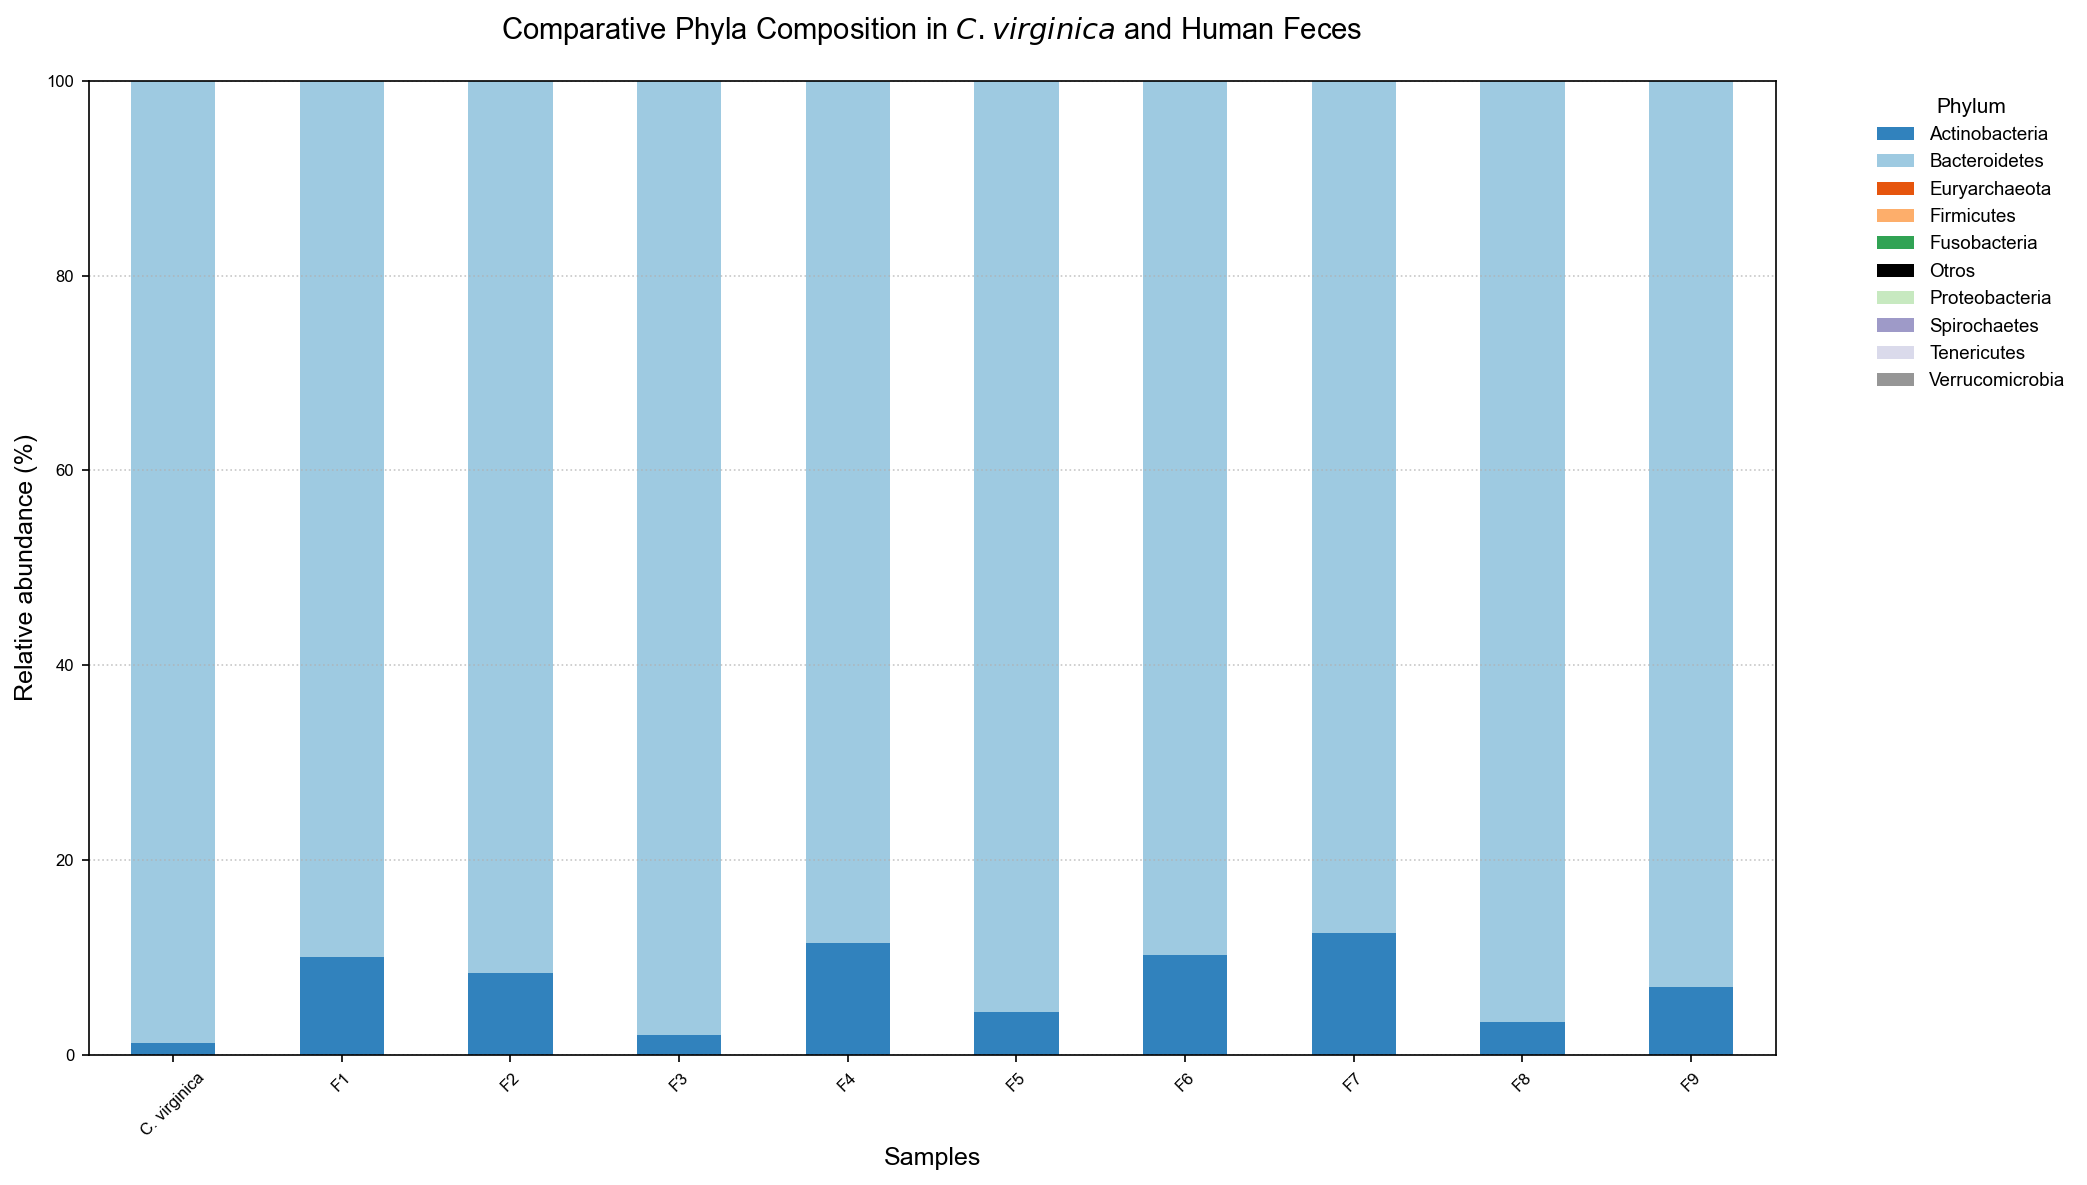

In [489]:
# Normalizar por muestra (filas)
df_rel = df_sorted_cvh_T.div(df_sorted_cvh_T.sum(axis=1), axis=0) * 100

# Top 18 filos más abundantes globalmente
top10_filos = df_rel.sum().sort_values(ascending=False).head(20).index.tolist()

# Filtrar y agregar "Otros"
df_top10 = df_rel[top10_filos].copy()
df_top10["Otros"] = (100 - df_top10.sum(axis=1)).clip(lower=0)
df_top10 = df_top10[top10_filos + ["Otros"]]

# Agrupar columnas con nombres repetidos
df_top10_grouped = df_top10.groupby(df_top10.columns, axis=1).sum()

# Crear paleta: negro solo para "Otros"
cmap = plt.cm.tab20c
colores_principales = [c for c in df_top10_grouped.columns if c != "Otros"]
colors_dict = {col: cmap(i / len(colores_principales)) for i, col in enumerate(colores_principales)}
if "Otros" in df_top10_grouped.columns:
    colors_dict["Otros"] = "black"
colors = [colors_dict[col] for col in df_top10_grouped.columns]

# Graficar
ax = df_top10_grouped.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 8),
    color=colors
)

# Leyenda
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    labels,
    title="Phylum",
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=False,
    fontsize=9,
    ncol=1
)

# Etiquetas y formato
plt.ylabel("Relative abundance (%)", fontsize=12)
plt.xlabel("Samples", fontsize=12)
plt.title("Comparative Phyla Composition in $\mathit{C. virginica}$ and Human Feces",
          fontsize=14, pad=20)
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### CV vs WA

In [490]:
print(df_cvw.info(show_counts=True))
print(df_cvw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 57 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Level_1                                     64 non-null     object 
 1   Level_2                                     64 non-null     object 
 2   Level_3                                     64 non-null     object 
 3   p-values                                    64 non-null     float64
 4   p-values (corrected)                        64 non-null     float64
 5   Effect size                                 64 non-null     float64
 6   Note                                        3 non-null      object 
 7   CV: mean rel. freq. (%)                     64 non-null     float64
 8   CV: std. dev. (%)                           64 non-null     float64
 9   WA: mean rel. freq. (%)                     64 non-null     float64
 10  WA: std. dev. (%

In [491]:
df_cvw = df_cvw[['Level_2', 'CV: mean rel. freq. (%)', 'AguaP1: rel. freq. (%)', 'AguaP2: rel. freq. (%)', 'AguaP3: rel. freq. (%)', 
          'AguaP4: rel. freq. (%)', 'AguaP5: rel. freq. (%)']]

print(df_cvw.info(show_counts=True))
print(df_cvw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Level_2                  64 non-null     object 
 1   CV: mean rel. freq. (%)  64 non-null     float64
 2   AguaP1: rel. freq. (%)   64 non-null     float64
 3   AguaP2: rel. freq. (%)   64 non-null     float64
 4   AguaP3: rel. freq. (%)   64 non-null     float64
 5   AguaP4: rel. freq. (%)   64 non-null     float64
 6   AguaP5: rel. freq. (%)   64 non-null     float64
dtypes: float64(6), object(1)
memory usage: 3.6+ KB
None
           Level_2  CV: mean rel. freq. (%)  AguaP1: rel. freq. (%)  \
0    Euryarchaeota                 0.000000                0.000000   
1  Verrucomicrobia                 0.001362                0.011198   
2    Acidobacteria                 0.000000                0.004799   
3  Verrucomicrobia                 0.003084                0.012798   


In [492]:
df_cvw.rename(columns={'Level_2': 'Filo',
                       'CV: mean rel. freq. (%)': 'C. virginica',
                       'AguaP1: rel. freq. (%)' : 'OCW', 
                       'AguaP2: rel. freq. (%)' : 'HZW', 
                       'AguaP3: rel. freq. (%)' : 'GZW',
                       'AguaP4: rel. freq. (%)' : 'RMW',
                       'AguaP5: rel. freq. (%)' : 'CZW'}, inplace=True)

print(df_cvw.info(show_counts=True))
print(df_cvw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Filo          64 non-null     object 
 1   C. virginica  64 non-null     float64
 2   OCW           64 non-null     float64
 3   HZW           64 non-null     float64
 4   GZW           64 non-null     float64
 5   RMW           64 non-null     float64
 6   CZW           64 non-null     float64
dtypes: float64(6), object(1)
memory usage: 3.6+ KB
None
              Filo  C. virginica       OCW       HZW       GZW  RMW       CZW
0    Euryarchaeota      0.000000  0.000000  0.000000  0.000000  0.0  0.000000
1  Verrucomicrobia      0.001362  0.011198  0.018066  0.018058  0.0  0.015215
2    Acidobacteria      0.000000  0.004799  0.006022  0.004515  0.0  0.000000
3  Verrucomicrobia      0.003084  0.012798  0.054197  0.036117  0.0  0.035502
4    Acidobacteria      0.000000  0.003199  0.012044  0.002257  

In [493]:
df_cvw.sort_values(by=['C. virginica', 'OCW', 'HZW', 'GZW', 'RMW', 'CZW'], ascending=False)
print(df_cvw.info(show_counts=True))
print(df_cvw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Filo          64 non-null     object 
 1   C. virginica  64 non-null     float64
 2   OCW           64 non-null     float64
 3   HZW           64 non-null     float64
 4   GZW           64 non-null     float64
 5   RMW           64 non-null     float64
 6   CZW           64 non-null     float64
dtypes: float64(6), object(1)
memory usage: 3.6+ KB
None
              Filo  C. virginica       OCW       HZW       GZW  RMW       CZW
0    Euryarchaeota      0.000000  0.000000  0.000000  0.000000  0.0  0.000000
1  Verrucomicrobia      0.001362  0.011198  0.018066  0.018058  0.0  0.015215
2    Acidobacteria      0.000000  0.004799  0.006022  0.004515  0.0  0.000000
3  Verrucomicrobia      0.003084  0.012798  0.054197  0.036117  0.0  0.035502
4    Acidobacteria      0.000000  0.003199  0.012044  0.002257  

In [494]:
print(df_cvw.info(show_counts=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Filo          64 non-null     object 
 1   C. virginica  64 non-null     float64
 2   OCW           64 non-null     float64
 3   HZW           64 non-null     float64
 4   GZW           64 non-null     float64
 5   RMW           64 non-null     float64
 6   CZW           64 non-null     float64
dtypes: float64(6), object(1)
memory usage: 3.6+ KB
None


In [495]:
#df_cvw[df_cvw['OCW'] != 'unknown_unclassified']



<>:52: SyntaxWarning: invalid escape sequence '\m'
<>:52: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\2688910215.py:52: SyntaxWarning: invalid escape sequence '\m'
  plt.title("Comparative Phyla composition in $\mathit{C.\ virginica}$ and Water samples")
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\2688910215.py:25: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df_top10_grouped = df_top10.groupby(df_top10.columns, axis=1).sum()
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\2688910215.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab10')


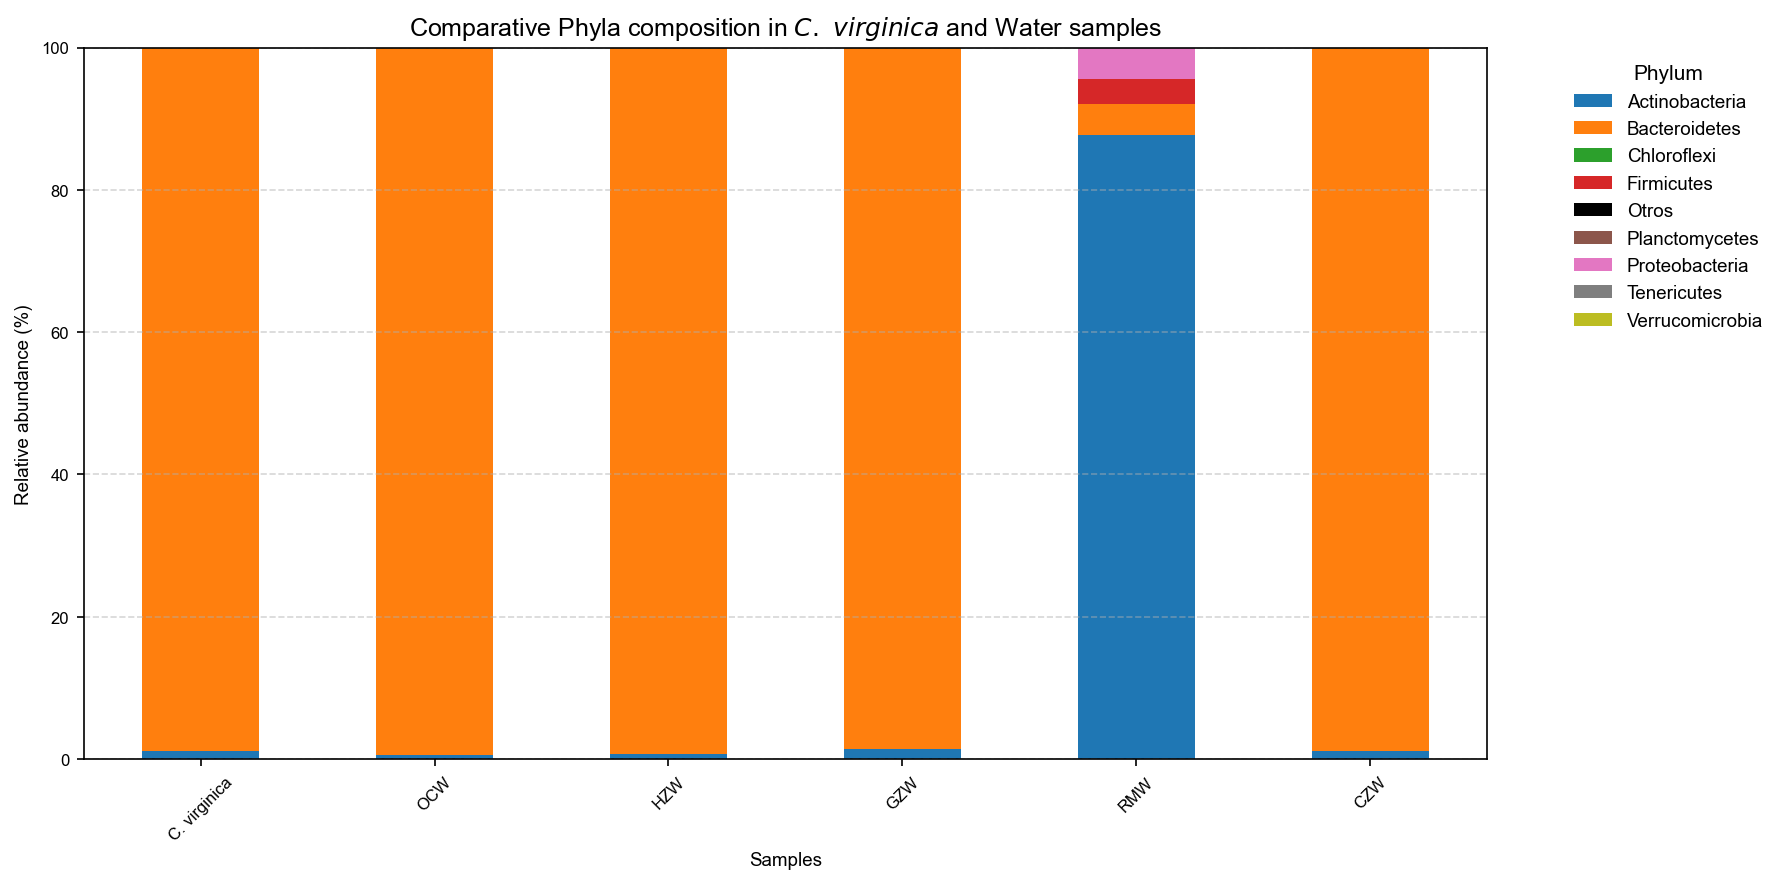

In [496]:
# Eliminar filos no clasificados

filos_a_eliminar = ['unknown_unclassified', 'Cyanobacteria_Chloroplast', 'Fusobacteria']
df_cvw = df_cvw[~df_cvw['Filo'].isin(filos_a_eliminar)]


# Establecer 'Filo' como índice y transponer
df_cvw.set_index('Filo', inplace=True)
df_cvw = df_cvw.T

# Normalizar
df_cvw_norm = df_cvw.div(df_cvw.sum(axis=1), axis=0) * 100

# Top 10 filos más abundantes globalmente
top10_filos = df_cvw_norm.sum(axis=0).sort_values(ascending=False).head(20).index.tolist()

# Filtrar top 10 y agregar "Otros"
df_top10 = df_cvw_norm[top10_filos].copy()
df_top10["Otros"] = 100 - df_top10.sum(axis=1)

# Reordenar columnas
df_top10 = df_top10[top10_filos + ["Otros"]]

# ✅ Agrupar columnas duplicadas por nombre (evita que 'Proteobacteria' se repita)
df_top10_grouped = df_top10.groupby(df_top10.columns, axis=1).sum()

# Crear colores: Dark2 para 10 filos + negro para 'Otros'
cmap = get_cmap('tab10')
colors_dict = {col: cmap(i / len(df_top10_grouped.columns)) for i, col in enumerate(df_top10_grouped.columns)}
if "Otros" in colors_dict:
    colors_dict["Otros"] = 'black'
colors = [colors_dict[col] for col in df_top10_grouped.columns]

# Graficar
ax = df_top10_grouped.plot(kind='bar', stacked=True, figsize=(12, 6), color=colors)

# Leyenda limpia y sin duplicados
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    labels,
    title="Phylum",
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=False,
    fontsize=9
)

# Personalización
plt.ylabel("Relative abundance (%)")
plt.xlabel("Samples")
plt.title("Comparative Phyla composition in $\mathit{C.\ virginica}$ and Water samples")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



### Agua vs HE

In [497]:
print(df_wvh.info(show_counts=True))
print(df_wvh.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 54 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Level_1                      64 non-null     object 
 1   Level_2                      64 non-null     object 
 2   Level_3                      64 non-null     object 
 3   p-values                     64 non-null     float64
 4   p-values (corrected)         64 non-null     float64
 5   Effect size                  64 non-null     float64
 6   Note                         1 non-null      object 
 7   HE: mean rel. freq. (%)      64 non-null     float64
 8   HE: std. dev. (%)            64 non-null     float64
 9   WA: mean rel. freq. (%)      64 non-null     float64
 10  WA: std. dev. (%)            64 non-null     float64
 11  HecesP10                     64 non-null     float64
 12  HecesP10: parent seq. count  64 non-null     float64
 13  HecesP10: rel. freq. (

In [498]:
df_wvh = df_wvh[['Level_2', 'HecesP6: rel. freq. (%)', 'HecesP7: rel. freq. (%)', 
          'HecesP8: rel. freq. (%)', 'HecesP9: rel. freq. (%)', 'HecesP10: rel. freq. (%)', 
          'HecesP11: rel. freq. (%)', 'HecesP12: rel. freq. (%)', 'HecesP13: rel. freq. (%)', 
          'HecesP14: rel. freq. (%)', 'AguaP1: rel. freq. (%)', 'AguaP2: rel. freq. (%)', 
          'AguaP3: rel. freq. (%)', 'AguaP4: rel. freq. (%)', 'AguaP5: rel. freq. (%)']]

print(df_wvh.info(show_counts=True))
print(df_wvh.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Level_2                   64 non-null     object 
 1   HecesP6: rel. freq. (%)   64 non-null     float64
 2   HecesP7: rel. freq. (%)   64 non-null     float64
 3   HecesP8: rel. freq. (%)   64 non-null     float64
 4   HecesP9: rel. freq. (%)   64 non-null     float64
 5   HecesP10: rel. freq. (%)  64 non-null     float64
 6   HecesP11: rel. freq. (%)  64 non-null     float64
 7   HecesP12: rel. freq. (%)  64 non-null     float64
 8   HecesP13: rel. freq. (%)  64 non-null     float64
 9   HecesP14: rel. freq. (%)  64 non-null     float64
 10  AguaP1: rel. freq. (%)    64 non-null     float64
 11  AguaP2: rel. freq. (%)    64 non-null     float64
 12  AguaP3: rel. freq. (%)    64 non-null     float64
 13  AguaP4: rel. freq. (%)    64 non-null     float64
 14  AguaP5: rel.

In [499]:
df_wvh.rename(columns={'Level_2': 'Filo',
                       'HecesP6: rel. freq. (%)': 'F1',
                       'HecesP7: rel. freq. (%)': 'F2',
                       'HecesP8: rel. freq. (%)': 'F3',
                       'HecesP9: rel. freq. (%)': 'F4',
                       'HecesP10: rel. freq. (%)': 'F5',
                       'HecesP11: rel. freq. (%)': 'F6',
                       'HecesP12: rel. freq. (%)': 'F7',
                       'HecesP13: rel. freq. (%)': 'F8',
                       'HecesP14: rel. freq. (%)': 'F9',
                       'AguaP1: rel. freq. (%)' : 'OCW', 
                       'AguaP2: rel. freq. (%)' : 'HZW', 
                       'AguaP3: rel. freq. (%)' : 'GZW',
                       'AguaP4: rel. freq. (%)' : 'RMW',
                       'AguaP5: rel. freq. (%)' : 'CZW'}, inplace=True)

print(df_wvh.info(show_counts=True))
print(df_wvh.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Filo    64 non-null     object 
 1   F1      64 non-null     float64
 2   F2      64 non-null     float64
 3   F3      64 non-null     float64
 4   F4      64 non-null     float64
 5   F5      64 non-null     float64
 6   F6      64 non-null     float64
 7   F7      64 non-null     float64
 8   F8      64 non-null     float64
 9   F9      64 non-null     float64
 10  OCW     64 non-null     float64
 11  HZW     64 non-null     float64
 12  GZW     64 non-null     float64
 13  RMW     64 non-null     float64
 14  CZW     64 non-null     float64
dtypes: float64(14), object(1)
memory usage: 7.6+ KB
None
                        Filo         F1         F2          F3         F4  \
0              Euryarchaeota   0.000000   0.000000  100.000000   0.000000   
1                 Firmicutes  58.780842  27.191202   69.

In [500]:
df_wvh.sort_values(by=['F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'OCW', 'HZW', 'GZW', 'RMW', 'CZW'], ascending=False)
print(df_wvh.info(show_counts=True))
print(df_wvh.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Filo    64 non-null     object 
 1   F1      64 non-null     float64
 2   F2      64 non-null     float64
 3   F3      64 non-null     float64
 4   F4      64 non-null     float64
 5   F5      64 non-null     float64
 6   F6      64 non-null     float64
 7   F7      64 non-null     float64
 8   F8      64 non-null     float64
 9   F9      64 non-null     float64
 10  OCW     64 non-null     float64
 11  HZW     64 non-null     float64
 12  GZW     64 non-null     float64
 13  RMW     64 non-null     float64
 14  CZW     64 non-null     float64
dtypes: float64(14), object(1)
memory usage: 7.6+ KB
None
                        Filo         F1         F2          F3         F4  \
0              Euryarchaeota   0.000000   0.000000  100.000000   0.000000   
1                 Firmicutes  58.780842  27.191202   69.

C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\2063189331.py:27: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df_top10 = df_top10.groupby(df_top10.columns, axis=1).sum()
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\2063189331.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab20')


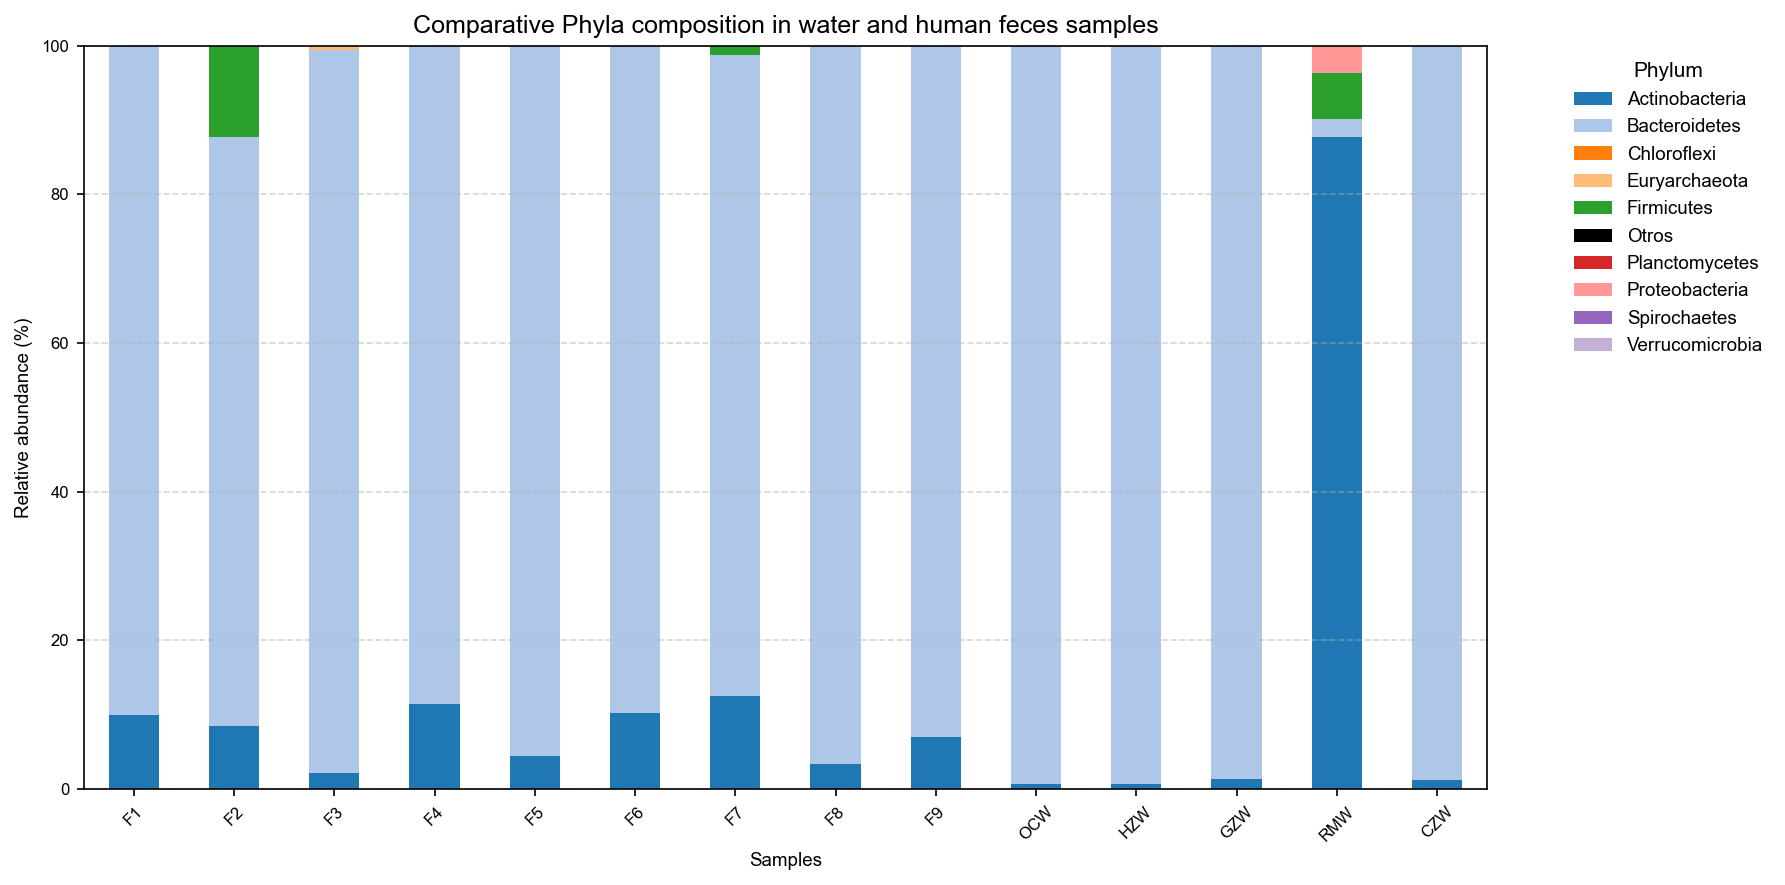

In [501]:
filos_a_eliminar_2 = ['unknown_unclassified', 'Cyanobacteria_Chloroplast']
df_wvh = df_wvh[~df_wvh['Filo'].isin(filos_a_eliminar_2)]

# Quitar 'unknown_unclassified'
df_wvh = df_wvh[df_wvh['Filo'] != 'unknown_unclassified'].copy()

# Establecer 'Filo' como índice y transponer
df_wvh.set_index('Filo', inplace=True)
df_wvh = df_wvh.T

# Normalizar por fila (muestra)
df_wvh_norm = df_wvh.div(df_wvh.sum(axis=1), axis=0) * 100

# Top 10 filos más abundantes globalmente
top10_filos = df_wvh_norm.sum().sort_values(ascending=False).head(18).index.tolist()

# Crear DataFrame de esos 10
df_top10 = df_wvh_norm[top10_filos].copy()

# Agregar columna "Otros"
df_top10["Otros"] = (100 - df_top10.sum(axis=1)).clip(lower=0)

# Asegurar orden correcto de columnas
df_top10 = df_top10[top10_filos + ["Otros"]]

# 🔧 Agrupar columnas con nombres duplicados
df_top10 = df_top10.groupby(df_top10.columns, axis=1).sum()

# Colores personalizados
cmap = get_cmap('tab20')
color_dict = {phylum: cmap(i) for i, phylum in enumerate(df_top10.columns)}
color_dict["Otros"] = "black"
colors = [color_dict[phylum] for phylum in df_top10.columns]

# Graficar
ax = df_top10.plot(kind='bar', stacked=True, figsize=(12, 6), color=colors)

# Leyenda sin marco
ax.legend(title="Phylum", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, fontsize=9)
plt.ylabel("Relative abundance (%)")
plt.xlabel("Samples")
plt.title("Comparative Phyla composition in water and human feces samples")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Para género

In [502]:
df_cvh_g = pd.read_csv('../statistics/16S/CV_vs_HE_genero_16S_clear.tsv', sep='\t')
df_cvw_g = pd.read_csv('../statistics/16S/CV_vs_WA_genero_16S_clear.tsv', sep='\t')
df_wvh_g = pd.read_csv('../statistics/16S/WA_vs_HE_genero_16S_clear.tsv', sep='\t')

In [503]:
print(df_cvh_g.info(show_counts=True))
print(df_cvh_g.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 72 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Level_1                                     541 non-null    object 
 1   Level_2                                     541 non-null    object 
 2   Level_3                                     541 non-null    object 
 3   Level_4                                     541 non-null    object 
 4   Level_5                                     541 non-null    object 
 5   Level_6                                     541 non-null    object 
 6   p-values                                    541 non-null    float64
 7   p-values (corrected)                        541 non-null    float64
 8   Effect size                                 541 non-null    float64
 9   Note                                        137 non-null    object 
 10  CV: mean rel. 

In [504]:
df_cvh_g = df_cvh_g[['p-values', 'Level_6', 'CV: mean rel. freq. (%)', 'HecesP6: rel. freq. (%)', 'HecesP7: rel. freq. (%)', 
          'HecesP8: rel. freq. (%)', 'HecesP9: rel. freq. (%)', 'HecesP10: rel. freq. (%)', 
          'HecesP11: rel. freq. (%)', 'HecesP12: rel. freq. (%)', 'HecesP13: rel. freq. (%)', 
          'HecesP14: rel. freq. (%)']]

print(df_cvh_g.info(show_counts=True))
print(df_cvh_g.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   p-values                  541 non-null    float64
 1   Level_6                   541 non-null    object 
 2   CV: mean rel. freq. (%)   541 non-null    float64
 3   HecesP6: rel. freq. (%)   541 non-null    float64
 4   HecesP7: rel. freq. (%)   541 non-null    float64
 5   HecesP8: rel. freq. (%)   541 non-null    float64
 6   HecesP9: rel. freq. (%)   541 non-null    float64
 7   HecesP10: rel. freq. (%)  541 non-null    float64
 8   HecesP11: rel. freq. (%)  541 non-null    float64
 9   HecesP12: rel. freq. (%)  541 non-null    float64
 10  HecesP13: rel. freq. (%)  541 non-null    float64
 11  HecesP14: rel. freq. (%)  541 non-null    float64
dtypes: float64(11), object(1)
memory usage: 50.8+ KB
None
   p-values             Level_6  CV: mean rel. freq. (%)  \
0  0.1

In [505]:
df_cvh_g.rename(columns={'Level_6': 'Género',
                       'CV: mean rel. freq. (%)': 'C. virginica',
                       'HecesP6: rel. freq. (%)': 'F1',
                       'HecesP7: rel. freq. (%)': 'F2',
                       'HecesP8: rel. freq. (%)': 'F3',
                       'HecesP9: rel. freq. (%)': 'F4',
                       'HecesP10: rel. freq. (%)': 'F5',
                       'HecesP11: rel. freq. (%)': 'F6',
                       'HecesP12: rel. freq. (%)': 'F7',
                       'HecesP13: rel. freq. (%)': 'F8',
                       'HecesP14: rel. freq. (%)': 'F9'}, inplace=True)

print(df_cvh_g.info())
display(df_cvh_g.head()) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      541 non-null    float64
 1   Género        541 non-null    object 
 2   C. virginica  541 non-null    float64
 3   F1            541 non-null    float64
 4   F2            541 non-null    float64
 5   F3            541 non-null    float64
 6   F4            541 non-null    float64
 7   F5            541 non-null    float64
 8   F6            541 non-null    float64
 9   F7            541 non-null    float64
 10  F8            541 non-null    float64
 11  F9            541 non-null    float64
dtypes: float64(11), object(1)
memory usage: 50.8+ KB
None


,p-values,Género,C. virginica,F1,F2,F3,F4,F5,F6,F7,F8,F9
0,0.128268,Methanobrevibacter,0.0,0.0,0.0,100.0,0.0,100.0,0.0,0.0,0.0,0.0
1,0.000000,Clostridium_XI,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2,0.000000,Exiguobacterium,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.000000,Actinomyces,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
4,0.000000,Fusibacter,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [506]:
df_cvh_g.sort_values(by='p-values', ascending=True,)
print(df_cvh_g.info(show_counts=True))
print(df_cvh_g.head(60).to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      541 non-null    float64
 1   Género        541 non-null    object 
 2   C. virginica  541 non-null    float64
 3   F1            541 non-null    float64
 4   F2            541 non-null    float64
 5   F3            541 non-null    float64
 6   F4            541 non-null    float64
 7   F5            541 non-null    float64
 8   F6            541 non-null    float64
 9   F7            541 non-null    float64
 10  F8            541 non-null    float64
 11  F9            541 non-null    float64
dtypes: float64(11), object(1)
memory usage: 50.8+ KB
None
        p-values                                Género  C. virginica          F1          F2          F3          F4          F5          F6          F7          F8          F9
0   1.282682e-01                    Methanobrevibacter   

In [507]:
df_filtered_11 = df_cvh_g[df_cvh_g['Género'].isin([''])]
df_cvh_g = pd.concat([df_cvh_g.head(20), df_filtered_11])
df_cvh_g = df_cvh_g.sort_index()
print(df_cvh_g.info(show_counts=True))
display(df_cvh_g.head(20))

<class 'pandas.core.frame.DataFrame'>
Index: 20 entries, 0 to 19
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      20 non-null     float64
 1   Género        20 non-null     object 
 2   C. virginica  20 non-null     float64
 3   F1            20 non-null     float64
 4   F2            20 non-null     float64
 5   F3            20 non-null     float64
 6   F4            20 non-null     float64
 7   F5            20 non-null     float64
 8   F6            20 non-null     float64
 9   F7            20 non-null     float64
 10  F8            20 non-null     float64
 11  F9            20 non-null     float64
dtypes: float64(11), object(1)
memory usage: 2.0+ KB
None


,p-values,Género,C. virginica,F1,F2,F3,F4,F5,F6,F7,F8,F9
0,1.282682e-01,Methanobrevibacter,0.000000,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000e+00,Clostridium_XI,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
2,0.000000e+00,Exiguobacterium,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000e+00,Actinomyces,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
4,0.000000e+00,Fusibacter,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.000000e+00,Rheinheimera,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,1.072435e-52,Pseudoalteromonas,99.977827,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,1.251576e-28,Algoriphagus,99.207632,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,2.016863e-18,Bacillariophyta,96.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,2.884014e-14,Dialister,0.000000,75.849822,95.000000,77.960526,76.724138,91.235955,83.439490,85.714286,60.952381,67.105263


<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\3006117469.py:33: SyntaxWarning: invalid escape sequence '\m'
  plt.title("Comparative Genus composition in $\mathit{C.\ virginica}$ and fecal samples")
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\3006117469.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_top20_genus["Otros"] = 100 - df_top20_genus.sum(axis=1)
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\3006117469.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cma

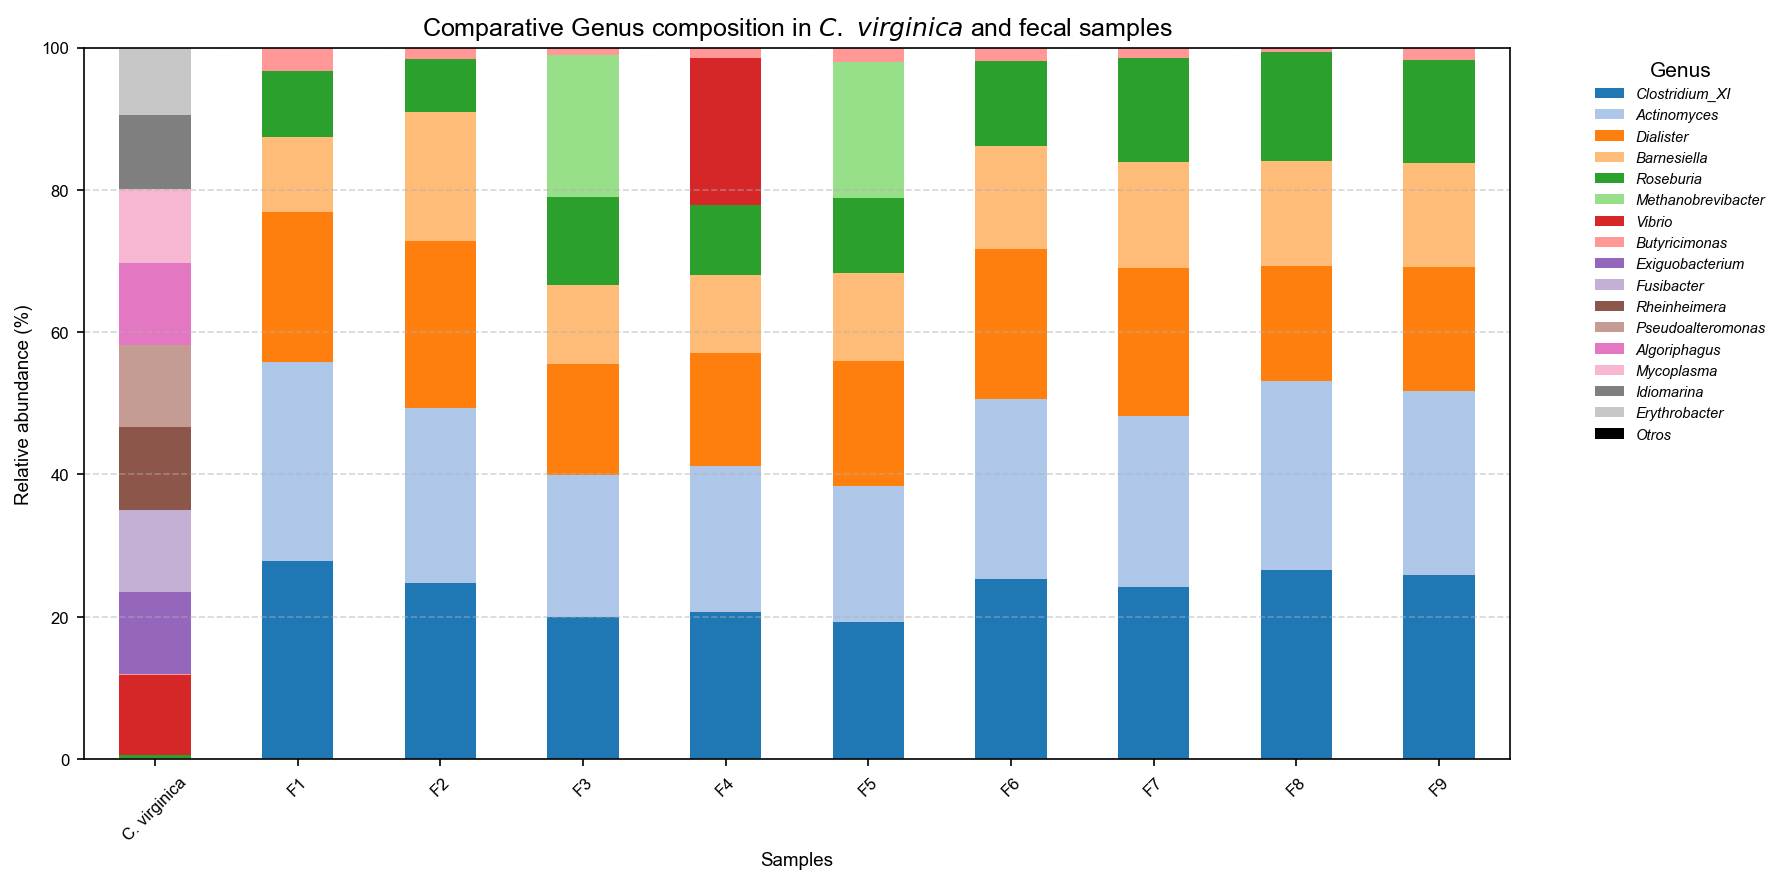

In [508]:
filos_a_eliminar_3 = ['unknown_unclassified', 'Bacillariophyta', 'Erysipelotrichaceae_incertae_sedis', 'Lachnospiracea_incertae_sedis', 'GpIIa']
df_cvh_g = df_cvh_g[~df_cvh_g['Género'].isin(filos_a_eliminar_3)]

# Eliminar la columna de p-values y transponer
df_cvh_g = df_cvh_g.drop(columns='p-values')
df_cvh_g.set_index('Género', inplace=True)
df_cvh_g = df_cvh_g.T

# Normalizar a porcentaje por muestra
df_cvh_norm_g = df_cvh_g.div(df_cvh_g.sum(axis=1), axis=0) * 100

# Identificar los 20 géneros más abundantes
top20_genus = df_cvh_norm_g.sum(axis=0).sort_values(ascending=False).head(20).index

# Filtrar el DataFrame para conservar solo los 20 géneros
df_top20_genus = df_cvh_norm_g[top20_genus]

# Agregar columna "Otros"
df_top20_genus["Otros"] = 100 - df_top20_genus.sum(axis=1)

# Generar lista de colores: tab20 para los 20 géneros + negro para "Otros"
cmap = get_cmap('tab20')
# tab20 tiene 20 colores únicos (después se repiten con tonos claros/oscuros)
# Si hay más de 20 géneros, considera usar tab20b/tab20c u otra paleta más larga
colors = [cmap(i) for i in range(len(top20_genus))] + ['black']

# Graficar
df_top20_genus.plot(kind='bar', stacked=True, figsize=(12, 6), color=colors)

# Personalización
plt.ylabel("Relative abundance (%)")
plt.xlabel("Samples")
plt.title("Comparative Genus composition in $\mathit{C.\ virginica}$ and fecal samples")
plt.legend(title="Genus", bbox_to_anchor=(1.05, 1), loc='upper left', prop={'style': 'italic'}, frameon=False)
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


### Ahora con Cv vs WA

In [509]:
print(df_cvw_g.info(show_counts=True))
print(df_cvw_g.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 60 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Level_1                                     541 non-null    object 
 1   Level_2                                     541 non-null    object 
 2   Level_3                                     541 non-null    object 
 3   Level_4                                     541 non-null    object 
 4   Level_5                                     541 non-null    object 
 5   Level_6                                     541 non-null    object 
 6   p-values                                    541 non-null    float64
 7   p-values (corrected)                        541 non-null    float64
 8   Effect size                                 541 non-null    float64
 9   Note                                        50 non-null     object 
 10  CV: mean rel. 

In [510]:
df_cvw_g = df_cvw_g[['p-values', 'Level_6', 'CV: mean rel. freq. (%)', 'AguaP1: rel. freq. (%)', 'AguaP2: rel. freq. (%)', 'AguaP3: rel. freq. (%)', 
          'AguaP4: rel. freq. (%)', 'AguaP5: rel. freq. (%)']]

print(df_cvw_g.info(show_counts=True))
print(df_cvw_g.head(60).to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   p-values                 541 non-null    float64
 1   Level_6                  541 non-null    object 
 2   CV: mean rel. freq. (%)  541 non-null    float64
 3   AguaP1: rel. freq. (%)   541 non-null    float64
 4   AguaP2: rel. freq. (%)   541 non-null    float64
 5   AguaP3: rel. freq. (%)   541 non-null    float64
 6   AguaP4: rel. freq. (%)   541 non-null    float64
 7   AguaP5: rel. freq. (%)   541 non-null    float64
dtypes: float64(7), object(1)
memory usage: 33.9+ KB
None
        p-values                   Level_6  CV: mean rel. freq. (%)  AguaP1: rel. freq. (%)  AguaP2: rel. freq. (%)  AguaP3: rel. freq. (%)  AguaP4: rel. freq. (%)  AguaP5: rel. freq. (%)
0   1.000000e+00        Methanobrevibacter                 0.000000                0.000000                0.0

In [511]:
df_cvw_g.rename(columns={'Level_6': 'Género',
                       'CV: mean rel. freq. (%)': 'C. virginica',
                       'AguaP1: rel. freq. (%)' : 'OCW', 
                       'AguaP2: rel. freq. (%)' : 'HZW', 
                       'AguaP3: rel. freq. (%)' : 'GZW',
                       'AguaP4: rel. freq. (%)' : 'RMW',
                       'AguaP5: rel. freq. (%)' : 'CZW'}, inplace=True)

print(df_cvw_g.info(show_counts=True))
print(df_cvw_g.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      541 non-null    float64
 1   Género        541 non-null    object 
 2   C. virginica  541 non-null    float64
 3   OCW           541 non-null    float64
 4   HZW           541 non-null    float64
 5   GZW           541 non-null    float64
 6   RMW           541 non-null    float64
 7   CZW           541 non-null    float64
dtypes: float64(7), object(1)
memory usage: 33.9+ KB
None
       p-values              Género  C. virginica        OCW  HZW       GZW  \
0  1.000000e+00  Methanobrevibacter      0.000000   0.000000  0.0  0.000000   
1  1.372280e-39   Pseudoalteromonas     99.977827   0.000000  0.0  0.000000   
2  5.642054e-08    Sphingobacterium     92.313896   3.846154  0.0  0.000000   
3  9.645427e-06       Fusobacterium     87.173653  14.285714  0.0  0.000000   
4  1.357658e-

In [512]:
df_cvw_g.sort_values(by='p-values', ascending=True)
print(df_cvw_g.info(show_counts=True))
print(df_cvw_g.head(60).to_string())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      541 non-null    float64
 1   Género        541 non-null    object 
 2   C. virginica  541 non-null    float64
 3   OCW           541 non-null    float64
 4   HZW           541 non-null    float64
 5   GZW           541 non-null    float64
 6   RMW           541 non-null    float64
 7   CZW           541 non-null    float64
dtypes: float64(7), object(1)
memory usage: 33.9+ KB
None
        p-values                    Género  C. virginica         OCW         HZW         GZW    RMW         CZW
0   1.000000e+00        Methanobrevibacter      0.000000    0.000000    0.000000    0.000000    0.0    0.000000
1   1.372280e-39         Pseudoalteromonas     99.977827    0.000000    0.000000    0.000000    0.0    0.000000
2   5.642054e-08          Sphingobacterium     92.313896    3.846154    

In [513]:
df_cvw_g = df_cvw_g.head(22)
print(df_cvw_g.info(show_counts=True))
print(df_cvw_g.head(22).to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      22 non-null     float64
 1   Género        22 non-null     object 
 2   C. virginica  22 non-null     float64
 3   OCW           22 non-null     float64
 4   HZW           22 non-null     float64
 5   GZW           22 non-null     float64
 6   RMW           22 non-null     float64
 7   CZW           22 non-null     float64
dtypes: float64(7), object(1)
memory usage: 1.5+ KB
None
        p-values              Género  C. virginica         OCW         HZW         GZW    RMW         CZW
0   1.000000e+00  Methanobrevibacter      0.000000    0.000000    0.000000    0.000000    0.0    0.000000
1   1.372280e-39   Pseudoalteromonas     99.977827    0.000000    0.000000    0.000000    0.0    0.000000
2   5.642054e-08    Sphingobacterium     92.313896    3.846154    0.000000    0.000000    0.0

In [514]:
df_cvw_g = pd.concat([df_cvw_g.head(22)])
df_cvw_g = df_cvw_g.sort_index()
print(df_cvw_g.info(show_counts=True))
print(df_cvw_g.head(22).to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      22 non-null     float64
 1   Género        22 non-null     object 
 2   C. virginica  22 non-null     float64
 3   OCW           22 non-null     float64
 4   HZW           22 non-null     float64
 5   GZW           22 non-null     float64
 6   RMW           22 non-null     float64
 7   CZW           22 non-null     float64
dtypes: float64(7), object(1)
memory usage: 1.5+ KB
None
        p-values              Género  C. virginica         OCW         HZW         GZW    RMW         CZW
0   1.000000e+00  Methanobrevibacter      0.000000    0.000000    0.000000    0.000000    0.0    0.000000
1   1.372280e-39   Pseudoalteromonas     99.977827    0.000000    0.000000    0.000000    0.0    0.000000
2   5.642054e-08    Sphingobacterium     92.313896    3.846154    0.000000    0.000000    0.0

<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\3694069033.py:32: SyntaxWarning: invalid escape sequence '\m'
  plt.title("Comparative Genus composition in $\mathit{C.\ virginica}$ and water samples")
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\3694069033.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab20')


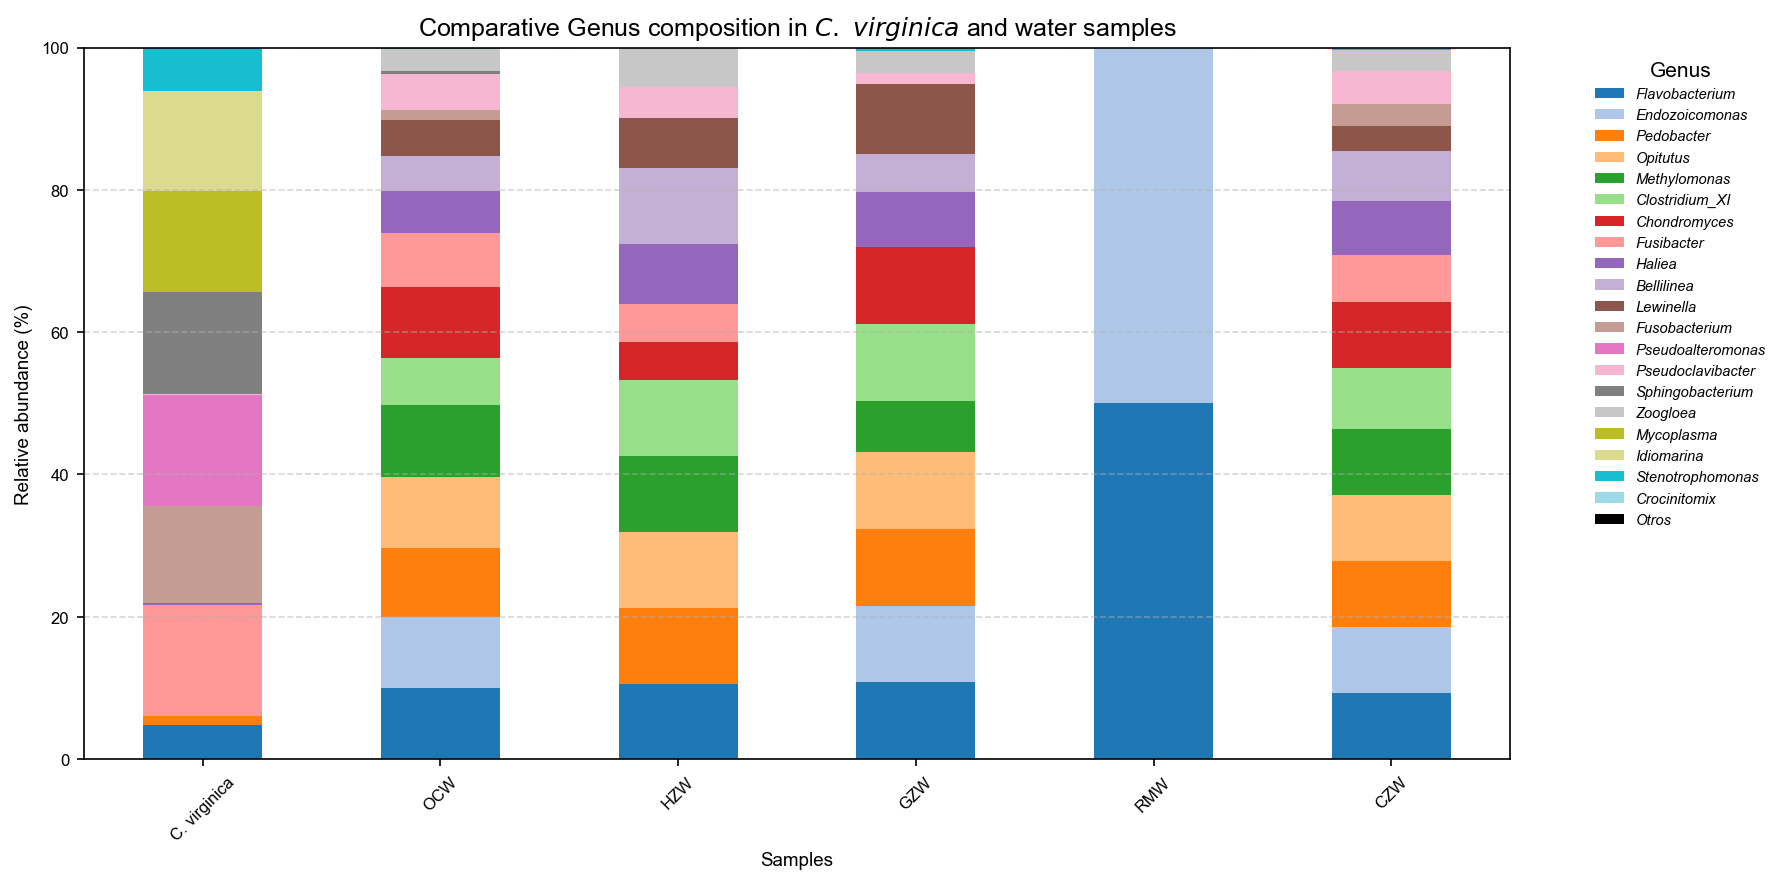

In [515]:
filos_a_eliminar_4 = ['unknown_unclassified', 'Gp1']
df_cvw_g = df_cvw_g[~df_cvw_g['Género'].isin(filos_a_eliminar_4)]


# Eliminar la columna 'p-values' y transponer
df_cvw_g = df_cvw_g.drop(columns='p-values')
df_cvw_g.set_index('Género', inplace=True)
df_cvw_g = df_cvw_g.T

# Normalizar a porcentajes por muestra
df_cvw_norm_g = df_cvw_g.div(df_cvw_g.sum(axis=1), axis=0) * 100

# Identificar los 20 géneros más abundantes globalmente
top20_genus = df_cvw_norm_g.sum(axis=0).sort_values(ascending=False).head(20).index

# Filtrar solo esos géneros
df_top20_genus = df_cvw_norm_g[top20_genus]

# Agregar columna "Otros"
df_top20_genus["Otros"] = 100 - df_top20_genus.sum(axis=1)

# Lista de colores: 20 de tab20 + negro
cmap = get_cmap('tab20')
colors = [cmap(i) for i in range(len(top20_genus))] + ['black']

# Graficar
df_top20_genus.plot(kind='bar', stacked=True, figsize=(12, 6), color=colors)

# Personalización
plt.ylabel("Relative abundance (%)")
plt.xlabel("Samples")
plt.title("Comparative Genus composition in $\mathit{C.\ virginica}$ and water samples")
plt.legend(title="Genus", bbox_to_anchor=(1.05, 1), loc='upper left', prop={'style': 'italic'}, frameon=False)
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


#### WA vs HE

In [516]:
print(df_wvh_g.info(show_counts=True))
display(df_wvh_g.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 57 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Level_1                      541 non-null    object 
 1   Level_2                      541 non-null    object 
 2   Level_3                      541 non-null    object 
 3   Level_4                      541 non-null    object 
 4   Level_5                      541 non-null    object 
 5   Level_6                      541 non-null    object 
 6   p-values                     541 non-null    float64
 7   p-values (corrected)         541 non-null    float64
 8   Effect size                  541 non-null    float64
 9   Note                         100 non-null    object 
 10  HE: mean rel. freq. (%)      541 non-null    float64
 11  HE: std. dev. (%)            541 non-null    float64
 12  WA: mean rel. freq. (%)      541 non-null    float64
 13  WA: std. dev. (%)   

,Level_1,Level_2,Level_3,Level_4,Level_5,Level_6,p-values,p-values (corrected),Effect size,Note,...,AguaP3,AguaP3: parent seq. count,AguaP3: rel. freq. (%),AguaP4,AguaP4: parent seq. count,AguaP4: rel. freq. (%),AguaP5,AguaP5: parent seq. count,AguaP5: rel. freq. (%),Unnamed: 56
0,Archaea,Euryarchaeota,Methanobacteria,Methanobacteriales,Methanobacteriaceae,Methanobrevibacter,2.901712e-01,2.901712e-01,0.092593,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,NaN
1,Bacteria,Actinobacteria,Actinobacteria,Actinomycetales,Actinomycetaceae,Actinomyces,0.000000e+00,0.000000e+00,1.000000,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,NaN
2,Bacteria,Proteobacteria,Gammaproteobacteria,Chromatiales,Chromatiaceae,Rheinheimera,5.152663e-30,5.152663e-30,0.999983,NaN,...,893.0,893.0,100.0,1.0,1.0,100.0,556.0,558.0,99.641577,NaN
3,Bacteria,Verrucomicrobia,Verrucomicrobiae,Verrucomicrobiales,Verrucomicrobiaceae,Akkermansia,4.766620e-09,4.766620e-09,0.947622,NaN,...,0.0,63.0,0.0,0.0,0.0,0.0,0.0,92.0,0.000000,NaN
4,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Porphyromonadaceae,Barnesiella,1.759571e-08,1.759571e-08,0.934946,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,0.000000,NaN


In [517]:
df_wvh_g = df_wvh_g[['p-values','Level_6', 'HecesP6: rel. freq. (%)', 'HecesP7: rel. freq. (%)', 
          'HecesP8: rel. freq. (%)', 'HecesP9: rel. freq. (%)', 'HecesP10: rel. freq. (%)', 
          'HecesP11: rel. freq. (%)', 'HecesP12: rel. freq. (%)', 'HecesP13: rel. freq. (%)', 
          'HecesP14: rel. freq. (%)', 'AguaP1: rel. freq. (%)', 'AguaP2: rel. freq. (%)', 
          'AguaP3: rel. freq. (%)', 'AguaP4: rel. freq. (%)', 'AguaP5: rel. freq. (%)']]

print(df_wvh_g.info(show_counts=True))
print(df_wvh_g.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   p-values                  541 non-null    float64
 1   Level_6                   541 non-null    object 
 2   HecesP6: rel. freq. (%)   541 non-null    float64
 3   HecesP7: rel. freq. (%)   541 non-null    float64
 4   HecesP8: rel. freq. (%)   541 non-null    float64
 5   HecesP9: rel. freq. (%)   541 non-null    float64
 6   HecesP10: rel. freq. (%)  541 non-null    float64
 7   HecesP11: rel. freq. (%)  541 non-null    float64
 8   HecesP12: rel. freq. (%)  541 non-null    float64
 9   HecesP13: rel. freq. (%)  541 non-null    float64
 10  HecesP14: rel. freq. (%)  541 non-null    float64
 11  AguaP1: rel. freq. (%)    541 non-null    float64
 12  AguaP2: rel. freq. (%)    541 non-null    float64
 13  AguaP3: rel. freq. (%)    541 non-null    float64
 14  AguaP4: re

In [518]:
df_wvh_g.rename(columns={'Level_6': 'Género',
                       'HecesP6: rel. freq. (%)': 'F1',
                       'HecesP7: rel. freq. (%)': 'F2',
                       'HecesP8: rel. freq. (%)': 'F3',
                       'HecesP9: rel. freq. (%)': 'F4',
                       'HecesP10: rel. freq. (%)': 'F5',
                       'HecesP11: rel. freq. (%)': 'F6',
                       'HecesP12: rel. freq. (%)': 'F7',
                       'HecesP13: rel. freq. (%)': 'F8',
                       'HecesP14: rel. freq. (%)': 'F9',
                       'AguaP1: rel. freq. (%)' : 'OCW', 
                       'AguaP2: rel. freq. (%)' : 'HZW', 
                       'AguaP3: rel. freq. (%)' : 'GZW',
                       'AguaP4: rel. freq. (%)' : 'RMW',
                       'AguaP5: rel. freq. (%)' : 'CZW'}, inplace=True)

print(df_wvh_g.info(show_counts=True))
print(df_wvh_g.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   p-values  541 non-null    float64
 1   Género    541 non-null    object 
 2   F1        541 non-null    float64
 3   F2        541 non-null    float64
 4   F3        541 non-null    float64
 5   F4        541 non-null    float64
 6   F5        541 non-null    float64
 7   F6        541 non-null    float64
 8   F7        541 non-null    float64
 9   F8        541 non-null    float64
 10  F9        541 non-null    float64
 11  OCW       541 non-null    float64
 12  HZW       541 non-null    float64
 13  GZW       541 non-null    float64
 14  RMW       541 non-null    float64
 15  CZW       541 non-null    float64
dtypes: float64(15), object(1)
memory usage: 67.8+ KB
None
       p-values              Género          F1          F2          F3  \
0  2.901712e-01  Methanobrevibacter    0.000000    0.000000

In [519]:
df_wvh_g.sort_values(by=['p-values'], ascending=False)
display(df_wvh_g.head())

,p-values,Género,F1,F2,F3,F4,F5,F6,F7,F8,F9,OCW,HZW,GZW,RMW,CZW
0,2.901712e-01,Methanobrevibacter,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
1,0.000000e+00,Actinomyces,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,0.000000,0.000000,0.0,0.0,0.000000
2,5.152663e-30,Rheinheimera,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,99.166667,100.0,100.0,99.641577
3,4.766620e-09,Akkermansia,60.869565,100.000000,100.000000,100.000000,98.809524,100.000000,100.000000,80.000000,100.000000,2.173913,0.000000,0.0,0.0,0.000000
4,1.759571e-08,Barnesiella,37.662338,73.333333,55.831266,53.278689,64.285714,57.264957,61.904762,55.681818,56.470588,0.000000,0.000000,0.0,0.0,0.000000


In [520]:
df_wvh_g = pd.concat([df_wvh_g.head(20)])
#df_wvh_g = df_wvh_g.sort_index()
display(df_wvh_g.head())

,p-values,Género,F1,F2,F3,F4,F5,F6,F7,F8,F9,OCW,HZW,GZW,RMW,CZW
0,2.901712e-01,Methanobrevibacter,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
1,0.000000e+00,Actinomyces,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,0.000000,0.000000,0.0,0.0,0.000000
2,5.152663e-30,Rheinheimera,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,99.166667,100.0,100.0,99.641577
3,4.766620e-09,Akkermansia,60.869565,100.000000,100.000000,100.000000,98.809524,100.000000,100.000000,80.000000,100.000000,2.173913,0.000000,0.0,0.0,0.000000
4,1.759571e-08,Barnesiella,37.662338,73.333333,55.831266,53.278689,64.285714,57.264957,61.904762,55.681818,56.470588,0.000000,0.000000,0.0,0.0,0.000000


C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\3343659296.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab20')


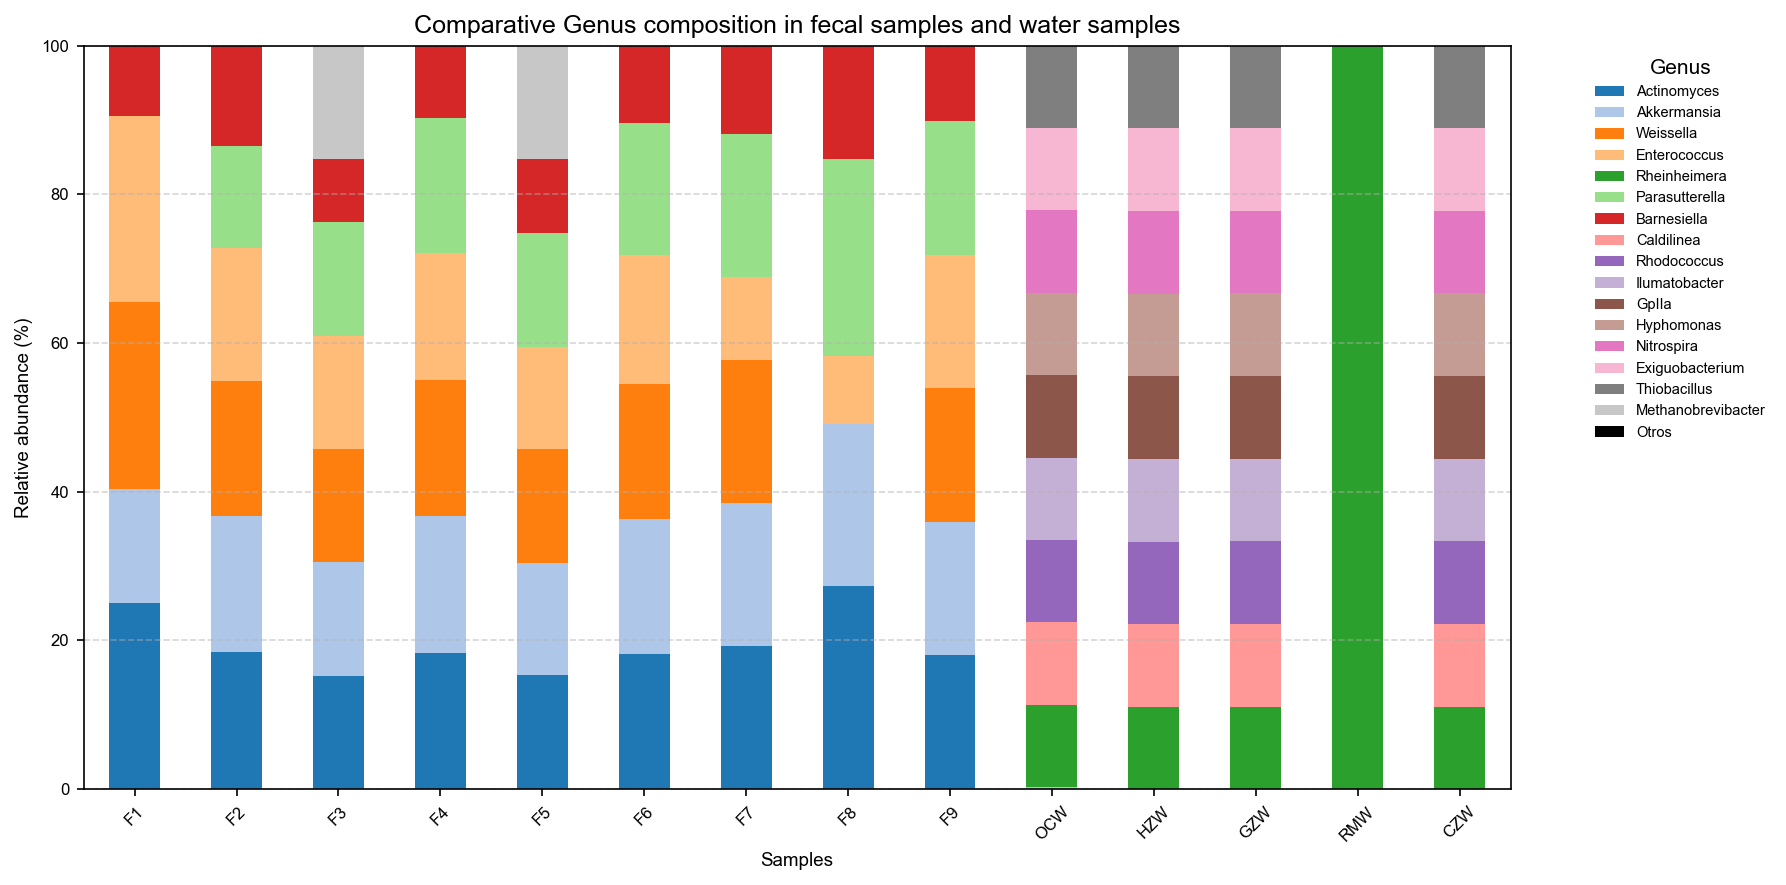

In [521]:
filos_a_eliminar_5 = ['unknown_unclassified', 'Gp16','Gp17']
df_wvh_g = df_wvh_g[~df_wvh_g['Género'].isin(filos_a_eliminar_5)]

# Eliminar columna 'p-values'
df_wvh_g = df_wvh_g.drop(columns='p-values')

# Poner 'Género' como índice (géneros en filas)
df_wvh_g.set_index('Género', inplace=True)

# Transponer para que las filas sean muestras y columnas géneros
df_wvh_g = df_wvh_g.T

# Filtrar columnas (géneros) que NO contengan 'incertae_sedis'
df_wvh_g = df_wvh_g.loc[:, ~df_wvh_g.columns.str.contains('incertae_sedis', case=False)]

# Normalizar filas (muestras) para que sumen 100%
df_wvh_norm_g = df_wvh_g.div(df_wvh_g.sum(axis=1), axis=0) * 100

# Obtener los 20 géneros más abundantes globalmente
top20_genus = df_wvh_norm_g.sum(axis=0).sort_values(ascending=False).head(20).index

# Crear DF solo con esos géneros
df_top20_genus = df_wvh_norm_g[top20_genus].copy()

# Agregar columna 'Otros' para completar 100%
df_top20_genus["Otros"] = 100 - df_top20_genus.sum(axis=1)

# Paleta de colores (20 géneros + negro para Otros)
cmap = get_cmap('tab20')
colors = [cmap(i) for i in range(len(top20_genus))] + ['black']

# Graficar barras apiladas
df_top20_genus.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=colors
)

# Personalización
plt.ylabel("Relative abundance (%)")
plt.xlabel("Samples")
plt.title("Comparative Genus composition in fecal samples and water samples")
plt.legend(title="Genus", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()




In [522]:
df_all_16SF = pd.read_csv('../statistics/16S/CV_vs_HE_vs_WA_filo_16S_clear.tsv', sep='\t')
df_all_16SG = pd.read_csv('../statistics/16S/CV_vs_HE_vs_WA_genero_16S_clear.tsv', sep='\t')

In [523]:
print(df_all_16SF.info())
display(df_all_16SF.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 86 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Level_1                                     64 non-null     object 
 1   Level_2                                     64 non-null     object 
 2   Level_3                                     64 non-null     object 
 3   p-values                                    64 non-null     float64
 4   p-values (corrected)                        64 non-null     float64
 5   Effect size                                 64 non-null     float64
 6   Note                                        0 non-null      float64
 7   CV: mean rel. freq. (%)                     64 non-null     float64
 8   CV: std. dev. (%)                           64 non-null     float64
 9   HE: mean rel. freq. (%)                     64 non-null     float64
 10  HE: std. dev. (%

,Level_1,Level_2,Level_3,p-values,p-values (corrected),Effect size,Note,CV: mean rel. freq. (%),CV: std. dev. (%),HE: mean rel. freq. (%),...,AguaP3,AguaP3: parent seq. count,AguaP3: rel. freq. (%),AguaP4,AguaP4: parent seq. count,AguaP4: rel. freq. (%),AguaP5,AguaP5: parent seq. count,AguaP5: rel. freq. (%),Unnamed: 85
0,Archaea,Euryarchaeota,Methanobacteria,1.781406e-01,1.781406e-01,0.151515,NaN,0.000000,0.000000,22.222222,...,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,NaN
1,Bacteria,Firmicutes,Clostridia,1.467943e-09,1.467943e-09,0.855877,NaN,3.655636,3.804350,51.849836,...,58.0,44301.0,0.130923,9.0,2583.0,0.348432,125.0,39434.0,0.316985,NaN
2,Bacteria,Proteobacteria,Gammaproteobacteria,1.591917e-07,1.591917e-07,0.774802,NaN,66.070554,13.086427,6.829547,...,14677.0,44301.0,33.130178,110.0,2583.0,4.258614,19444.0,39434.0,49.307704,NaN
3,Bacteria,Bacteroidetes,Bacteroidia,3.544342e-06,3.544342e-06,0.697373,NaN,3.923881,3.130738,16.830664,...,5.0,44301.0,0.011286,0.0,2583.0,0.000000,8.0,39434.0,0.020287,NaN
4,Bacteria,Firmicutes,Erysipelotrichia,7.816368e-05,7.816368e-05,0.593690,NaN,0.017254,0.019258,2.246857,...,5.0,44301.0,0.011286,0.0,2583.0,0.000000,3.0,39434.0,0.007608,NaN


In [524]:
df_all_16SF = df_all_16SF[['p-values','Level_2', 'CV: mean rel. freq. (%)', 'HecesP6: rel. freq. (%)', 'HecesP7: rel. freq. (%)', 
          'HecesP8: rel. freq. (%)', 'HecesP9: rel. freq. (%)', 'HecesP10: rel. freq. (%)', 
          'HecesP11: rel. freq. (%)', 'HecesP12: rel. freq. (%)', 'HecesP13: rel. freq. (%)', 
          'HecesP14: rel. freq. (%)', 'AguaP1: rel. freq. (%)', 'AguaP2: rel. freq. (%)', 
          'AguaP3: rel. freq. (%)', 'AguaP4: rel. freq. (%)', 'AguaP5: rel. freq. (%)']]

print(df_all_16SF.info())
display(df_all_16SF.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   p-values                  64 non-null     float64
 1   Level_2                   64 non-null     object 
 2   CV: mean rel. freq. (%)   64 non-null     float64
 3   HecesP6: rel. freq. (%)   64 non-null     float64
 4   HecesP7: rel. freq. (%)   64 non-null     float64
 5   HecesP8: rel. freq. (%)   64 non-null     float64
 6   HecesP9: rel. freq. (%)   64 non-null     float64
 7   HecesP10: rel. freq. (%)  64 non-null     float64
 8   HecesP11: rel. freq. (%)  64 non-null     float64
 9   HecesP12: rel. freq. (%)  64 non-null     float64
 10  HecesP13: rel. freq. (%)  64 non-null     float64
 11  HecesP14: rel. freq. (%)  64 non-null     float64
 12  AguaP1: rel. freq. (%)    64 non-null     float64
 13  AguaP2: rel. freq. (%)    64 non-null     float64
 14  AguaP3: rel.

,p-values,Level_2,CV: mean rel. freq. (%),HecesP6: rel. freq. (%),HecesP7: rel. freq. (%),HecesP8: rel. freq. (%),HecesP9: rel. freq. (%),HecesP10: rel. freq. (%),HecesP11: rel. freq. (%),HecesP12: rel. freq. (%),HecesP13: rel. freq. (%),HecesP14: rel. freq. (%),AguaP1: rel. freq. (%),AguaP2: rel. freq. (%),AguaP3: rel. freq. (%),AguaP4: rel. freq. (%),AguaP5: rel. freq. (%)
0,1.781406e-01,Euryarchaeota,0.000000,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1.467943e-09,Firmicutes,3.655636,58.780842,27.191202,69.919958,29.081729,59.643702,47.757224,40.555471,64.942746,68.775647,0.631879,0.192701,0.130923,0.348432,0.316985
2,1.591917e-07,Proteobacteria,66.070554,5.043541,15.290036,0.649708,15.592147,0.911727,1.553955,21.565050,0.425854,0.433905,28.140197,72.383476,33.130178,4.258614,49.307704
3,3.544342e-06,Bacteroidetes,3.923881,14.656507,8.099306,21.621622,11.070500,24.589914,16.176075,7.227206,27.358758,20.676085,0.220758,0.018066,0.011286,0.000000,0.020287
4,7.816368e-05,Firmicutes,0.017254,4.859700,4.649077,0.743396,1.190700,1.335164,2.653677,1.753586,2.195514,0.840901,0.009598,0.006022,0.011286,0.000000,0.007608


In [525]:
df_all_16SF = df_all_16SF.rename(columns={'Level_2': 'Filo',
                          'CV: mean rel. freq. (%)': 'C. virginica',
                          'HecesP6: rel. freq. (%)': 'F1',
                          'HecesP7: rel. freq. (%)': 'F2',
                          'HecesP8: rel. freq. (%)': 'F3',
                          'HecesP9: rel. freq. (%)': 'F4',
                          'HecesP10: rel. freq. (%)': 'F5',
                          'HecesP11: rel. freq. (%)': 'F6',
                          'HecesP12: rel. freq. (%)': 'F7',
                          'HecesP13: rel. freq. (%)': 'F8',
                          'HecesP14: rel. freq. (%)': 'F9',
                          'AguaP1: rel. freq. (%)' : 'OCW', 
                          'AguaP2: rel. freq. (%)' : 'HZW', 
                          'AguaP3: rel. freq. (%)' : 'GZW',
                          'AguaP4: rel. freq. (%)' : 'RMW',
                          'AguaP5: rel. freq. (%)' : 'CZW'})
print(df_all_16SF.info())
display(df_all_16SF.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      64 non-null     float64
 1   Filo          64 non-null     object 
 2   C. virginica  64 non-null     float64
 3   F1            64 non-null     float64
 4   F2            64 non-null     float64
 5   F3            64 non-null     float64
 6   F4            64 non-null     float64
 7   F5            64 non-null     float64
 8   F6            64 non-null     float64
 9   F7            64 non-null     float64
 10  F8            64 non-null     float64
 11  F9            64 non-null     float64
 12  OCW           64 non-null     float64
 13  HZW           64 non-null     float64
 14  GZW           64 non-null     float64
 15  RMW           64 non-null     float64
 16  CZW           64 non-null     float64
dtypes: float64(16), object(1)
memory usage: 8.6+ KB
None


,p-values,Filo,C. virginica,F1,F2,F3,F4,F5,F6,F7,F8,F9,OCW,HZW,GZW,RMW,CZW
0,1.781406e-01,Euryarchaeota,0.000000,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1.467943e-09,Firmicutes,3.655636,58.780842,27.191202,69.919958,29.081729,59.643702,47.757224,40.555471,64.942746,68.775647,0.631879,0.192701,0.130923,0.348432,0.316985
2,1.591917e-07,Proteobacteria,66.070554,5.043541,15.290036,0.649708,15.592147,0.911727,1.553955,21.565050,0.425854,0.433905,28.140197,72.383476,33.130178,4.258614,49.307704
3,3.544342e-06,Bacteroidetes,3.923881,14.656507,8.099306,21.621622,11.070500,24.589914,16.176075,7.227206,27.358758,20.676085,0.220758,0.018066,0.011286,0.000000,0.020287
4,7.816368e-05,Firmicutes,0.017254,4.859700,4.649077,0.743396,1.190700,1.335164,2.653677,1.753586,2.195514,0.840901,0.009598,0.006022,0.011286,0.000000,0.007608


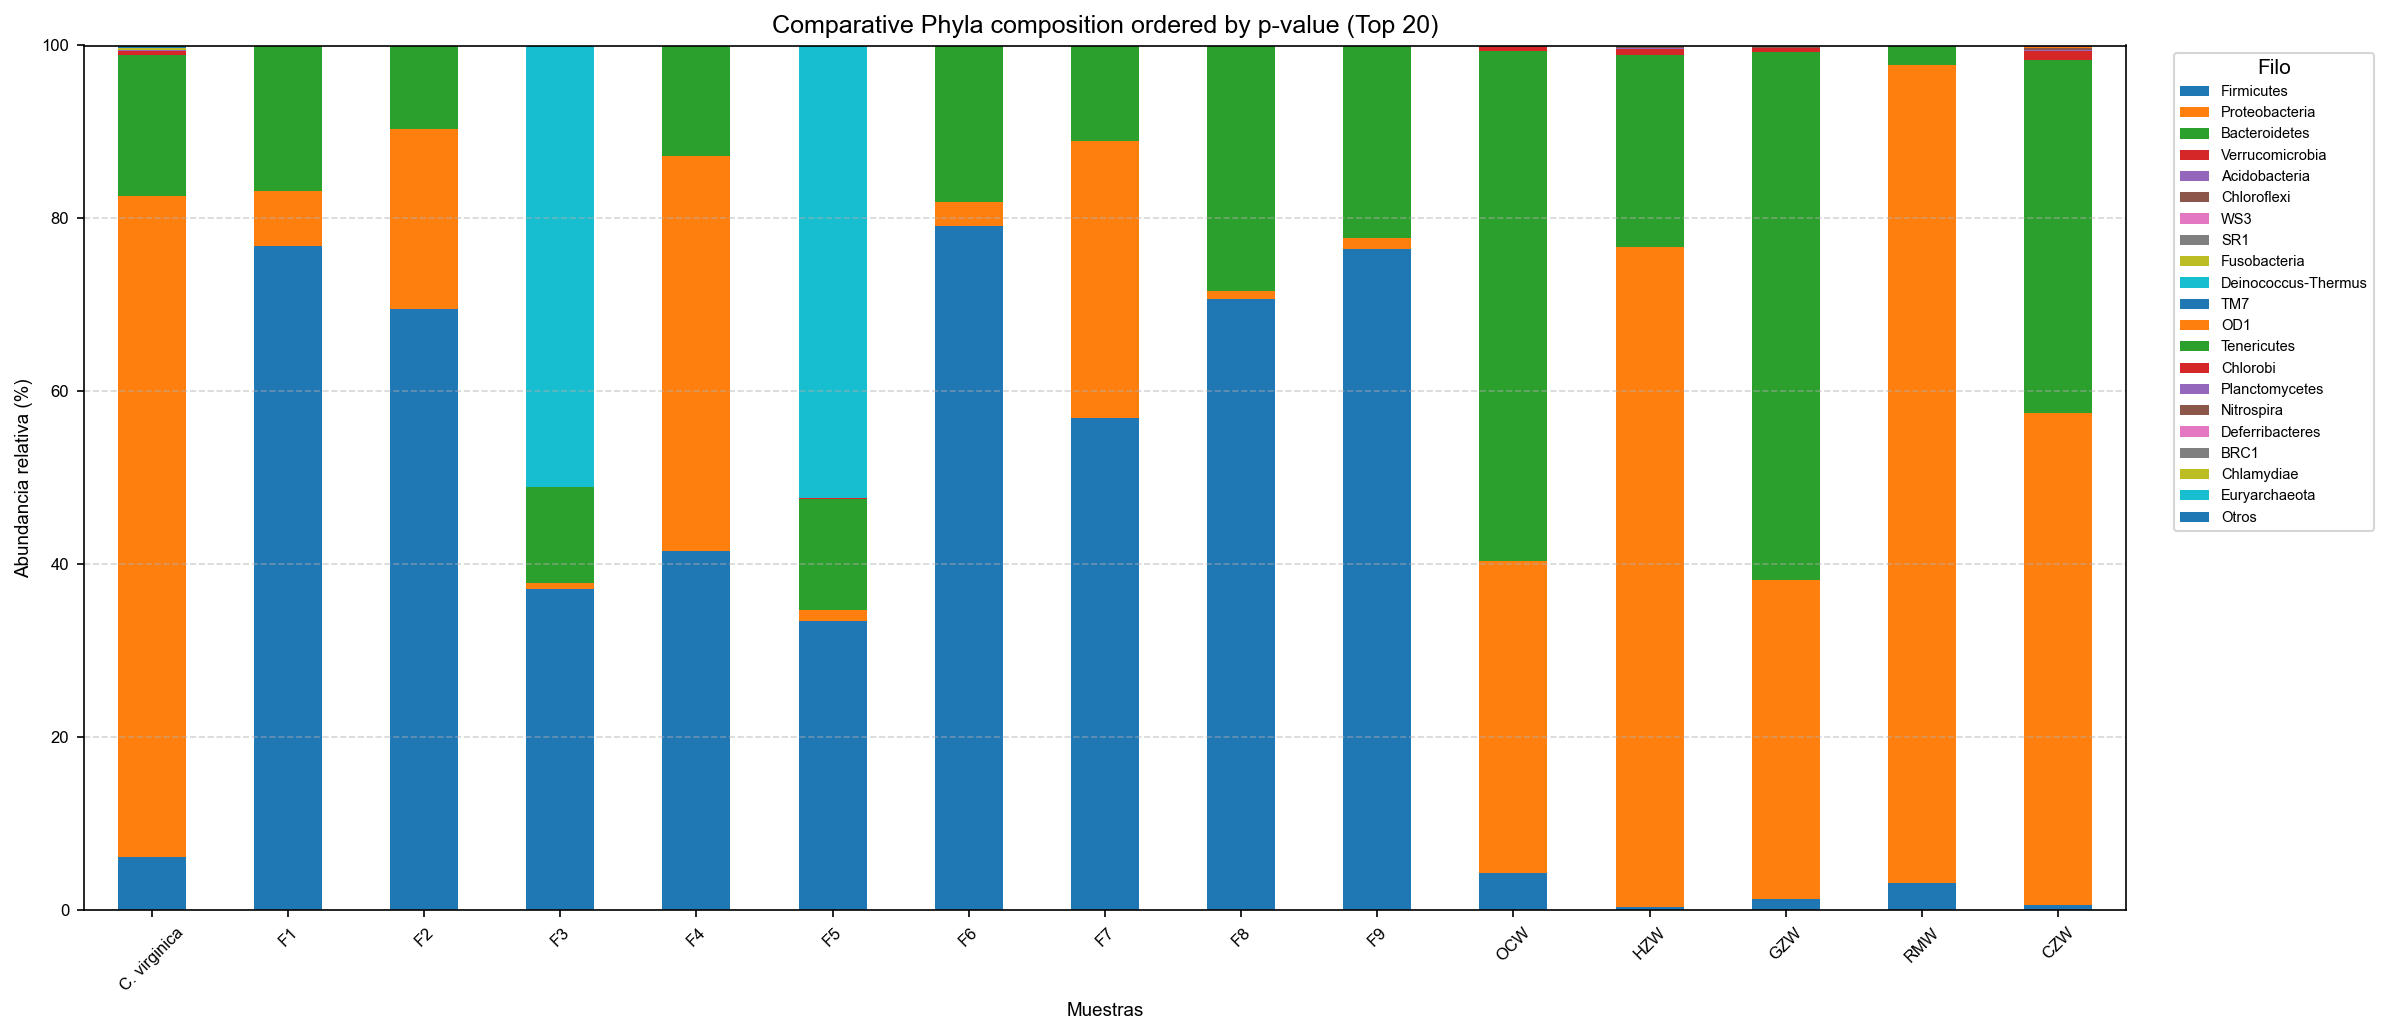

In [526]:
# 1) Filtra filos no deseados
filos_a_eliminar_6 = ['unknown_unclassified', 'Cyanobacteria_Chloroplast']
df = df_all_16SF[~df_all_16SF['Filo'].isin(filos_a_eliminar_6)].copy()

# 2) Ordena por p-value (menor = más significativo)
df = df.sort_values('p-values', ascending=True)

# 3) Extrae los 20 filos más significativos (sin duplicar filos)
top20_filos = (
    df.drop_duplicates(subset='Filo', keep='first')
      .head(20)['Filo']
      .tolist()
)

# 4) Agrega por Filo **solo** columnas de abundancia (excluye 'Filo' y 'p-values')
cols_abund = [c for c in df.columns if c not in ['Filo', 'p-values']]
df_grouped = df.groupby('Filo')[cols_abund].sum()

# 5) Mantén el orden por p-value y arma la matriz muestra × filo
df_grouped = df_grouped.loc[top20_filos]          # columnas = muestras, filas = 20 filos
df_norm = df_grouped.T.apply(pd.to_numeric, errors='coerce').fillna(0)

# 6) Normaliza por muestra a 100%
df_norm = df_norm.div(df_norm.sum(axis=1), axis=0) * 100

# 7) Calcula 'Otros' (todo lo que no está en el top 20)
df_norm['Otros'] = 100 - df_norm[top20_filos].sum(axis=1)

# 8) Grafica (stacked bar). Se respeta el orden por p-value en la leyenda
ax = df_norm[top20_filos + ['Otros']].plot(
    kind='bar', stacked=True, figsize=(16,7)
)

plt.ylabel("Abundancia relativa (%)")
plt.xlabel("Muestras")
plt.title("Comparative Phyla composition ordered by p-value (Top 20)")
plt.legend(title="Filo", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()







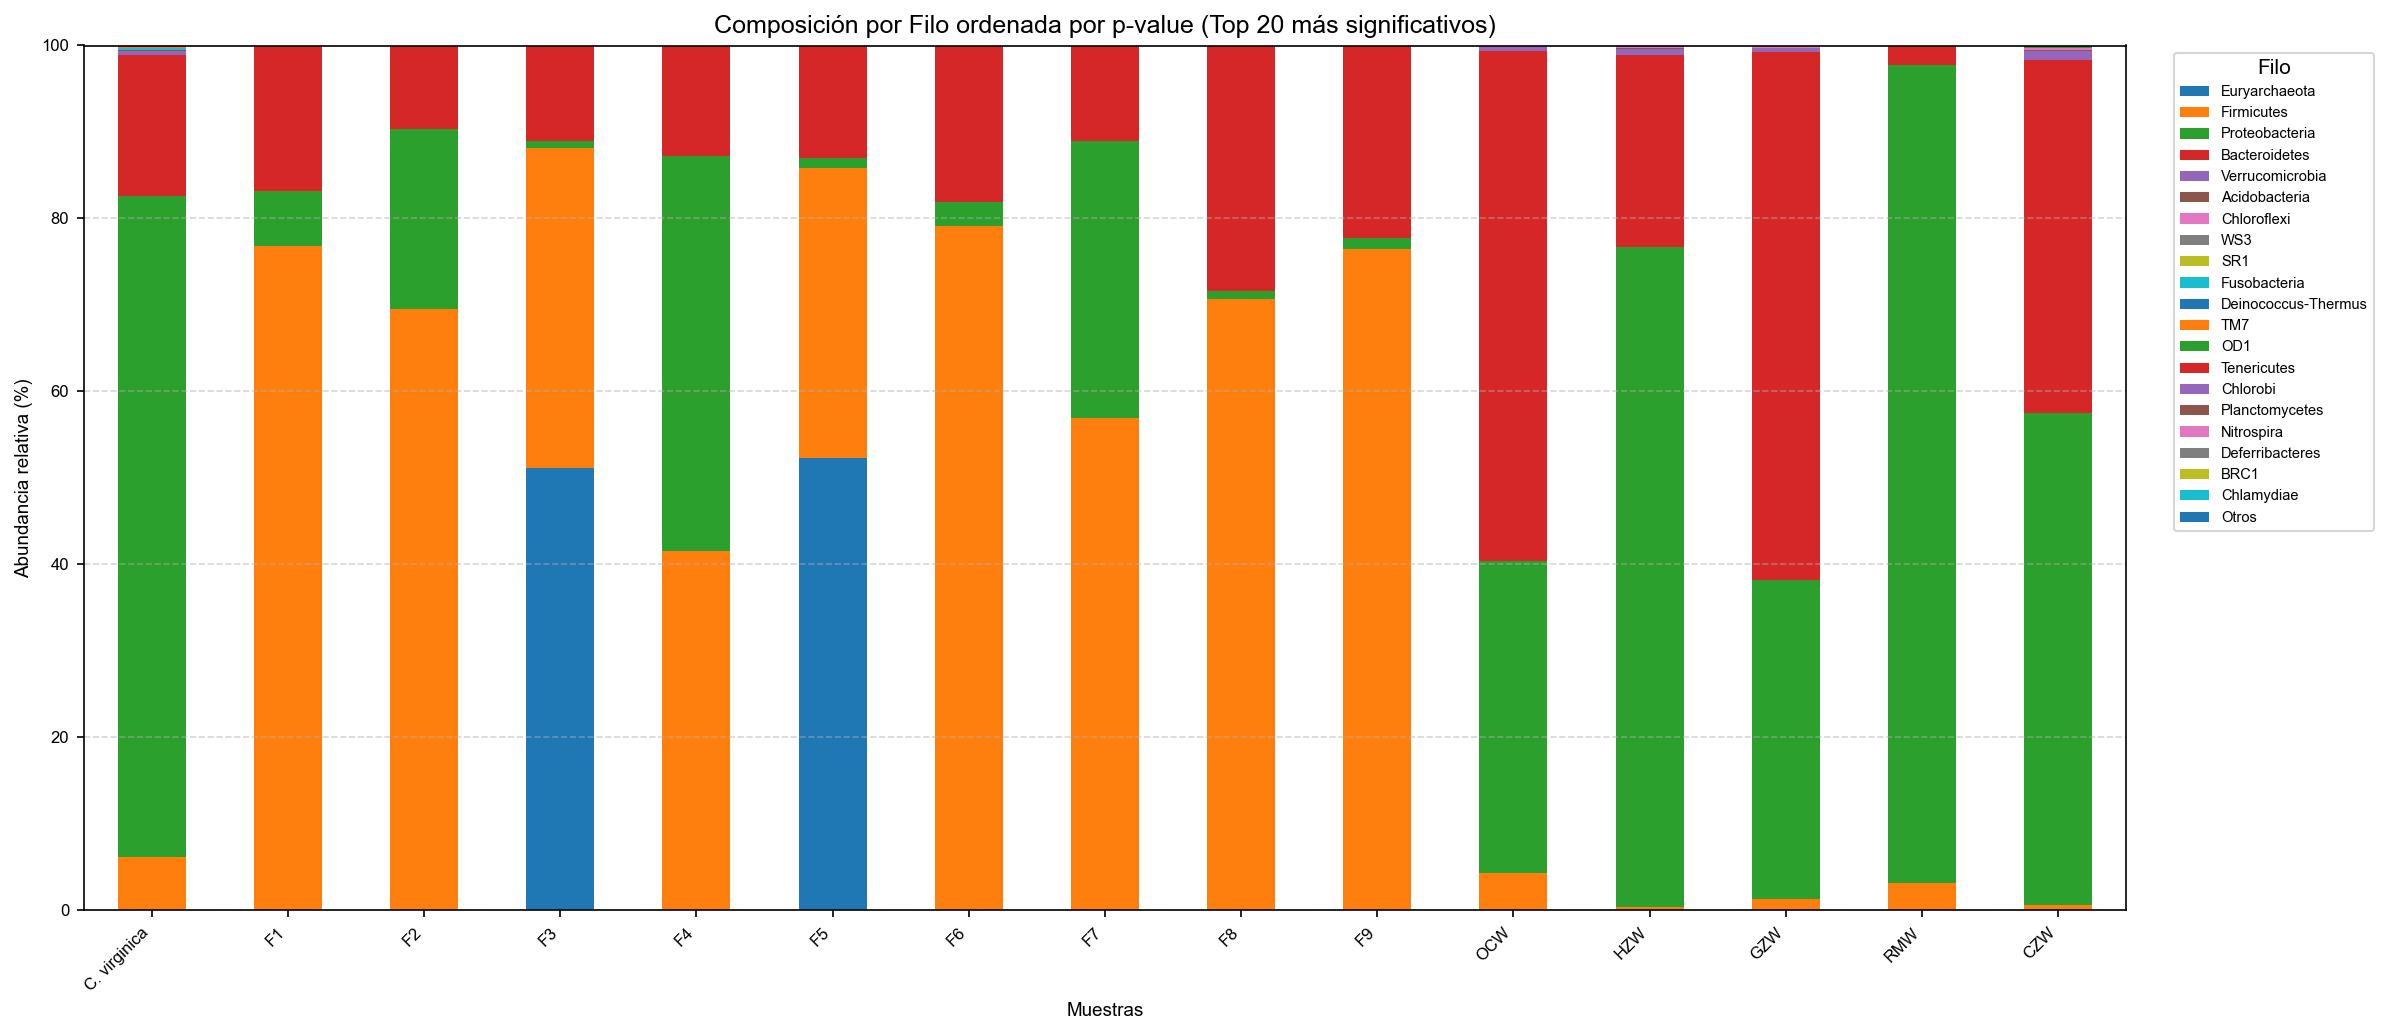


>>> Tabla compacta (Top20): Filo | p_min | % promedio | significativo
               Filo        p_min  Porcentaje_promedio_%  Significativo(p<=0.005)
         Firmicutes 1.467943e-09              37.178173                     True
     Proteobacteria 1.591917e-07              32.604782                     True
      Bacteroidetes 3.544342e-06              22.950971                     True
    Verrucomicrobia 2.095941e-04               0.223500                     True
      Acidobacteria 3.379773e-04               0.033612                     True
        Chloroflexi 4.544551e-04               0.036055                     True
                WS3 1.833514e-03               0.000593                     True
                SR1 4.310184e-03               0.001456                     True
       Fusobacteria 6.233591e-03               0.020498                    False
Deinococcus-Thermus 1.102271e-02               0.003930                    False
                TM7 1.156695e-02      

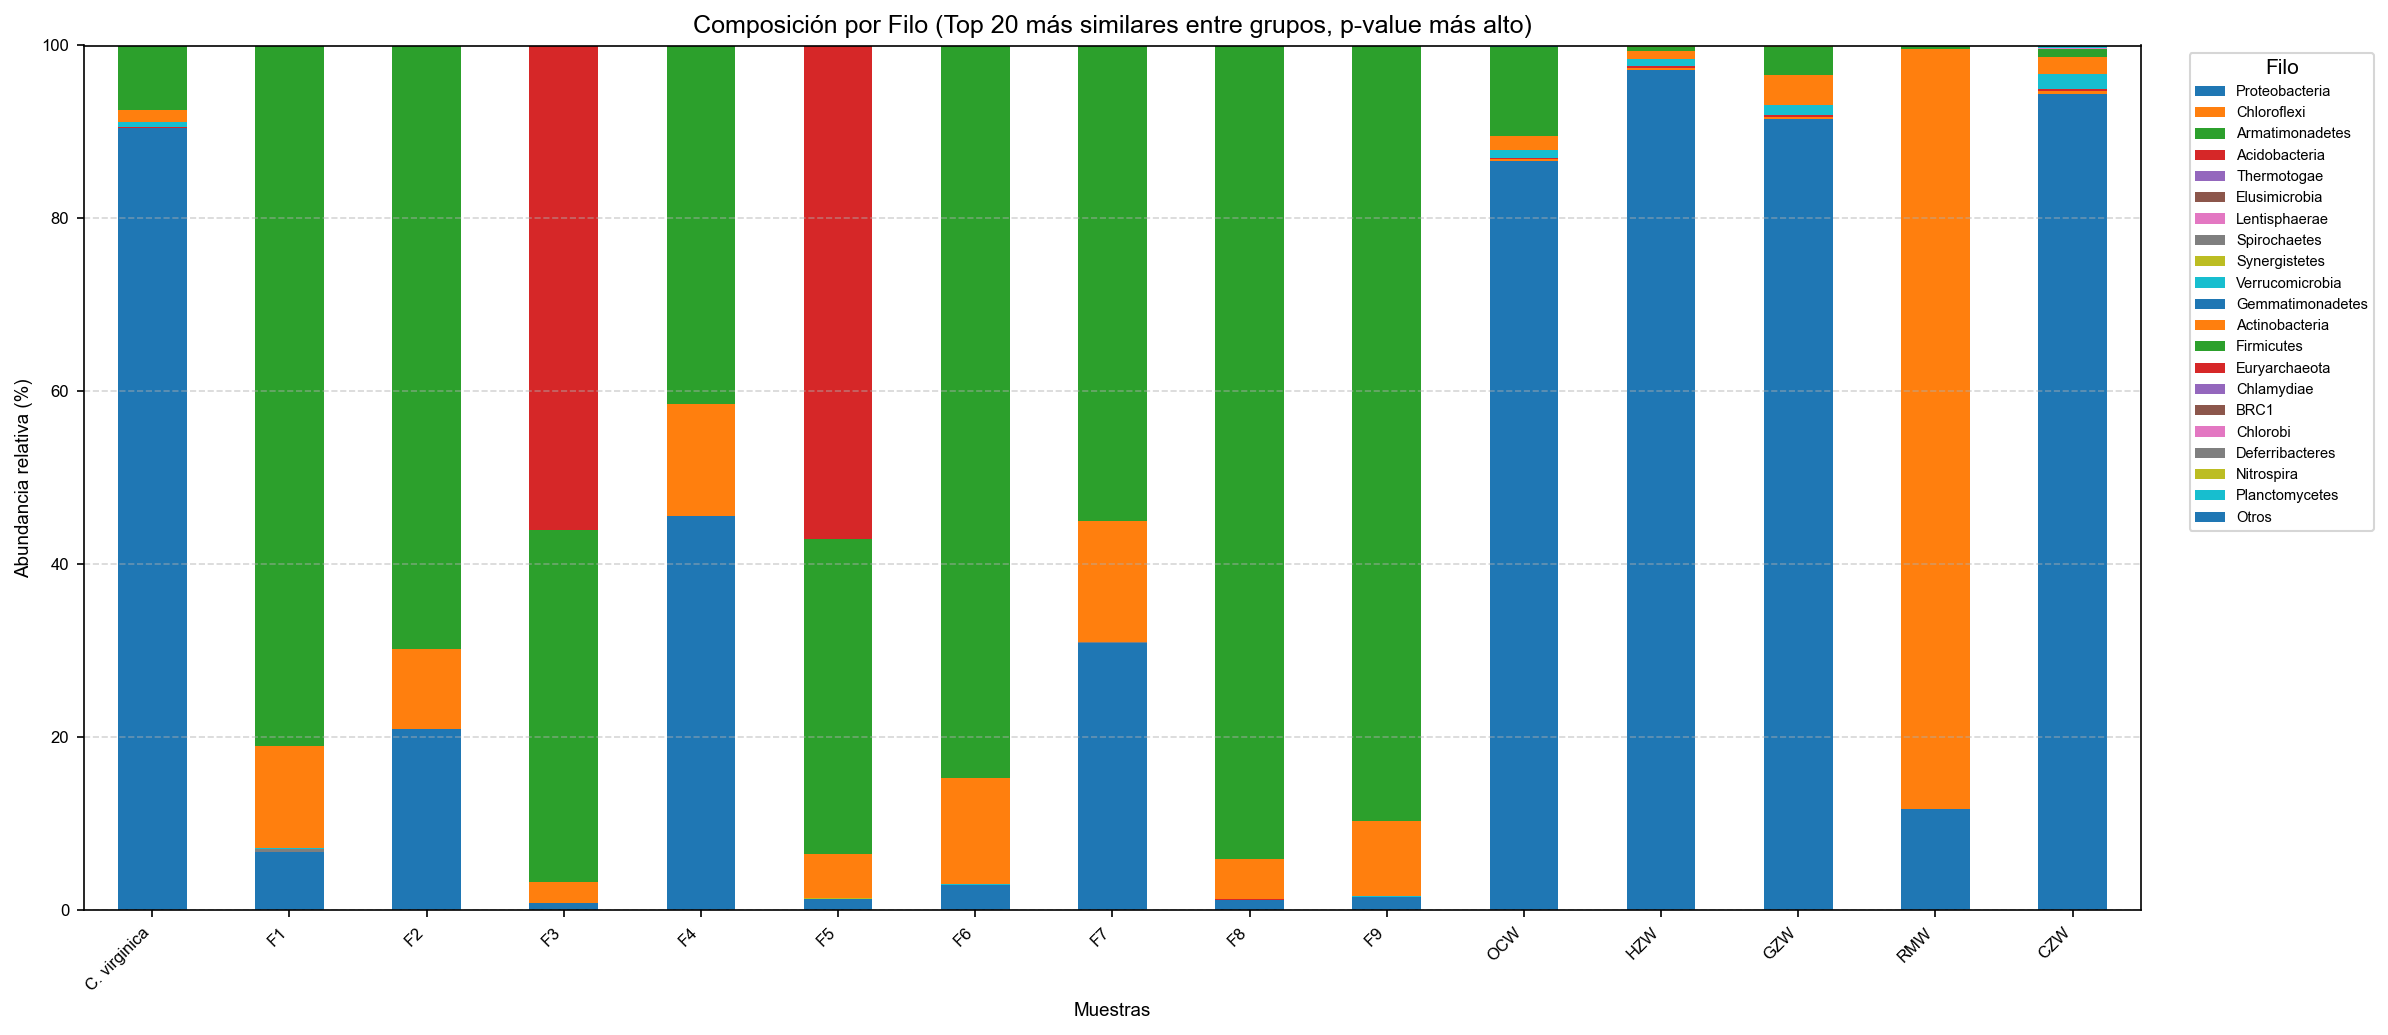

In [527]:
# ================================
# Top 20 por p-value (más SIGNIFICATIVOS)
# ================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ----------------
# 0) CONFIG
# ----------------
# Filos a eliminar (ajusta si hace falta):
filos_a_eliminar = ['unknown_unclassified', 'Cyanobacteria_Chloroplast']

# Umbral de significancia que usarás en el manuscrito (ajústalo si corresponde)
ALPHA = 0.005

# ----------------
# 1) Filtra y ordena por p-value
# ----------------
df = df_all_16SF.copy()

# Asegurar tipos
df['p-values'] = pd.to_numeric(df['p-values'], errors='coerce')

# Filtrar filos no deseados
df = df[~df['Filo'].isin(filos_a_eliminar)].copy()

# Ordenar por p-value ascendente (menor = más significativo)
df_altos = df[df['p-values'] > 0.5]  # o el valor que definas como "alto"
df_altos = df_altos.sort_values('p-values', ascending=False)


# ----------------
# 2) Seleccionar Top 20 (único p por filo: el más bajo)
# ----------------
top20_filos = (
    df.drop_duplicates(subset='Filo', keep='first')  # conserva el p más bajo por Filo
      .head(20)['Filo']
      .tolist()
)

# ----------------
# 3) Agregar por Filo solo columnas de abundancia (excluye 'Filo' y 'p-values')
# ----------------
cols_abund = [c for c in df.columns if c not in ['Filo', 'p-values']]
df_grouped = df.groupby('Filo')[cols_abund].sum()

# Mantener el orden de top20_filos
df_grouped = df_grouped.loc[top20_filos]

# ----------------
# 4) Matriz muestra×filo y normalización a 100% por muestra
# ----------------
df_norm = df_grouped.T.apply(pd.to_numeric, errors='coerce').fillna(0)
df_norm = df_norm.div(df_norm.sum(axis=1), axis=0) * 100  # normaliza por muestra

# Calcular "Otros"
df_norm['Otros'] = 100 - df_norm[top20_filos].sum(axis=1)

# ----------------
# 5) Plot: Stacked bar (Top 20 por p más bajo)
# ----------------
ax = df_norm[top20_filos + ['Otros']].plot(
    kind='bar',
    stacked=True,
    figsize=(16, 7)
)
plt.ylabel("Abundancia relativa (%)")
plt.xlabel("Muestras")
plt.title("Composición por Filo ordenada por p-value (Top 20 más significativos)")
plt.legend(title="Filo", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# ----------------
# 6) Tabla resumen para manuscrito
# ----------------
# p mínimo por Filo (entre todas sus comparaciones/registros)
p_min_por_filo = df.groupby('Filo')['p-values'].min()

# Tomar p_min solo de los Top20 seleccionados
p_min_top20 = p_min_por_filo.loc[top20_filos]

# Porcentajes por muestra para los Top20
tabla_porcentajes = df_norm[top20_filos].copy()
# Orden de columnas = por p-value (ya respetado en top20_filos)
tabla_porcentajes = tabla_porcentajes[top20_filos]

# Tabla “wide” por muestra y filo, con p_min aparte
# (útil para revisar y/o exportar)
# Si quieres una versión larga (tidy), descomenta el bloque más abajo.
tabla_top20 = tabla_porcentajes.copy()
# Añadir una fila con la etiqueta del umbral (opcional solo informativo):
# (No afecta cálculos, solo referencia visual si exportas a CSV)
tabla_top20.attrs['alpha'] = ALPHA

# También puedes crear una tabla compacta: Filo | p_min | %promedio_global
promedio_global = tabla_porcentajes.mean(axis=0)  # promedio % por Filo en todas las muestras
tabla_compacta = (
    pd.DataFrame({
        'Filo': promedio_global.index,
        'p_min': p_min_top20.values,
        'Porcentaje_promedio_%': promedio_global.values
    })
    .sort_values('p_min', ascending=True)
    .reset_index(drop=True)
)

# Marcar cuáles cumplen significancia
tabla_compacta['Significativo(p<={})'.format(ALPHA)] = tabla_compacta['p_min'] <= ALPHA

# Mostrar tablas en pantalla (opcional)
print("\n>>> Tabla compacta (Top20): Filo | p_min | % promedio | significativo")
print(tabla_compacta.to_string(index=False))

# (Opcional) Versión "larga/tidy" con muestras en una columna:
# tidy_top20 = (
#     tabla_porcentajes.reset_index()
#     .melt(id_vars='index', var_name='Filo', value_name='Porcentaje_%')
#     .rename(columns={'index': 'Muestra'})
#     .merge(p_min_top20.reset_index().rename(columns={'p-values': 'p_min'}), on='Filo', how='left')
# )

# ----------------
# 7) Exportar CSV (opcional)
# ----------------
# tabla_top20.to_csv("top20_por_muestra_%_wide.csv", index=True, encoding='utf-8')
# tabla_compacta.to_csv("top20_compacto_con_pmin.csv", index=False, encoding='utf-8')

# =====================================================
# (Opcional) Top 20 más "SIMILARES" entre grupos (p más alto)
# =====================================================
df_desc = df.sort_values('p-values', ascending=False)
top20_similares = (
    df_desc.drop_duplicates(subset='Filo', keep='first')
           .head(20)['Filo'].tolist()
)

df_grouped_sim = df.groupby('Filo')[cols_abund].sum().loc[top20_similares]

df_norm_sim = df_grouped_sim.T.apply(pd.to_numeric, errors='coerce').fillna(0)
df_norm_sim = df_norm_sim.div(df_norm_sim.sum(axis=1), axis=0) * 100

df_norm_sim['Otros'] = 100 - df_norm_sim[top20_similares].sum(axis=1)

ax2 = df_norm_sim[top20_similares + ['Otros']].plot(
    kind='bar',
    stacked=True,
    figsize=(16, 7)
)
plt.ylabel("Abundancia relativa (%)")
plt.xlabel("Muestras")
plt.title("Composición por Filo (Top 20 más similares entre grupos, p-value más alto)")
plt.legend(title="Filo", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


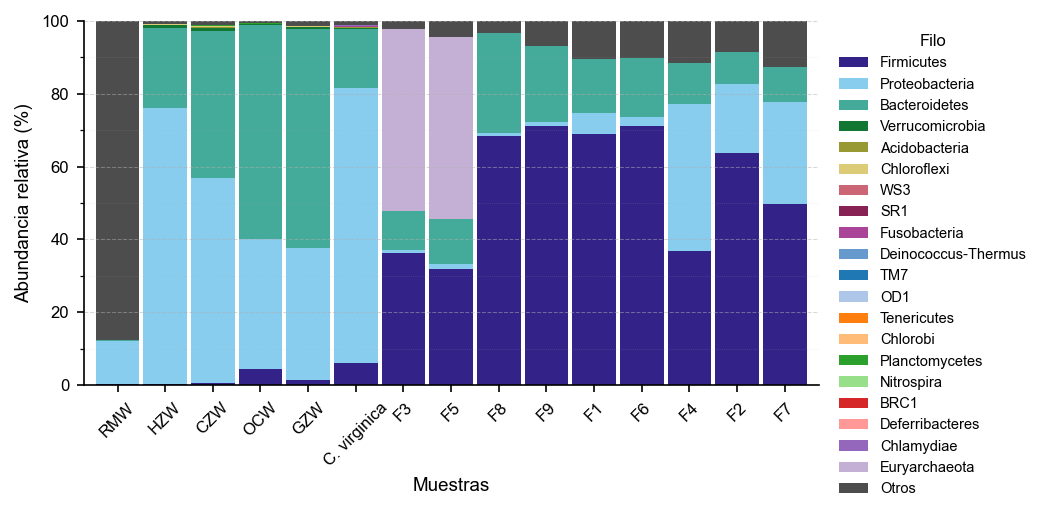

In [528]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import re

# ----- opcional: ordenar muestras por similitud si hay scipy -----
try:
    from scipy.spatial.distance import pdist
    from scipy.cluster.hierarchy import linkage, leaves_list
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False

# =========================
# 0) Copia y normaliza la forma de 'Filo'
# =========================
df_all_18SF = df_all_16SF.copy()  # requiere: 'Filo', 'p-values' (si existe) y columnas de muestras

# Si 'Filo' no está como columna, intenta recuperarlo del índice
if 'Filo' not in df.columns:
    if df.index.name == 'Filo':
        df = df.reset_index()
    else:
        df = df.reset_index()
        if 'Filo' not in df.columns:
            if 'index' in df.columns:
                df = df.rename(columns={'index': 'Filo'})
            else:
                raise KeyError("No se encontró la columna 'Filo' ni estaba como índice.")

# Arreglo de etiquetas conocidas
df['Filo'] = df['Filo'].replace({
    'Cryptista:nucl': 'Cryptista',
    'Cryptophyta:nucl': 'Cryptophyta'
})

# =========================
# 1) Filtrado y columnas de muestras
# =========================
filos_a_eliminar = ['Eukaryota_unclassified', 'Streptophyta', 'Cryptophyta:nucl']
df = df[~df['Filo'].isin(filos_a_eliminar)]

# Columnas de abundancia (todas menos 'Filo', 'p-values')
cols_muestras = [c for c in df.columns if c not in ['Filo', 'p-values']]
# Quita 'SumaTotal' si estuviera como "muestra"
if 'SumaTotal' in cols_muestras:
    cols_muestras.remove('SumaTotal')

df[cols_muestras] = df[cols_muestras].apply(pd.to_numeric, errors='coerce').fillna(0)

# =========================
# 2) Agregación por Filo (abundancias y p-values)
# =========================
abund_por_filo = df.groupby('Filo')[cols_muestras].sum()

# p-value más bajo por Filo (más significativo)
if 'p-values' in df.columns:
    pval_por_filo = df.groupby('Filo')['p-values'].min()
else:
    pval_por_filo = pd.Series(index=abund_por_filo.index, dtype=float)

# =========================
# 3) Top 20 por p-value (ASC)  ← selección y orden definidos por significancia
# =========================
if pval_por_filo.notna().any():
    top20_filos = pval_por_filo.sort_values(ascending=True).head(20).index.tolist()
    orden_por_pval = top20_filos[:]  # ya están por p-value ascendente
else:
    # sin p-values, cae al top-20 por abundancia
    top20_filos = abund_por_filo.sum(axis=1).sort_values(ascending=False).head(20).index.tolist()
    orden_por_pval = top20_filos

# =========================
# 4) Normalización correcta a % sobre el TOTAL por muestra
# =========================
# total por muestra considerando TODOS los filos
total_por_muestra = abund_por_filo.sum(axis=0).replace(0, np.nan)

# matriz normalizada completa a %
full_norm = (abund_por_filo.T
             .div(total_por_muestra, axis=0)
             .fillna(0) * 100)

# submatriz solo con top20 en el orden pedido
top_norm = full_norm[orden_por_pval].copy()

# =========================
# 5) "Otros" = 100 - suma(top20) por muestra
# =========================
otros_pct = (100 - top_norm.sum(axis=1)).clip(lower=0)
mat_norm = top_norm.copy()
mat_norm['Otros'] = otros_pct

# =========================
# 6) (Opcional) Ordenar muestras por similitud (Bray–Curtis)
# =========================
if SCIPY_OK and mat_norm.shape[0] > 2:
    try:
        D = pdist(mat_norm.values, metric='braycurtis')
        Z = linkage(D, method='average')
        order_idx = leaves_list(Z)
        mat_norm = mat_norm.iloc[order_idx]
    except Exception:
        pass  # si falla, deja el orden actual

# =========================
# 6.1) Reordenación manual: poner "C. virginica" antes de "F3"
# =========================
def mover_antes(lista, item, antes_de):
    if item in lista and antes_de in lista:
        lista = [x for x in lista if x != item]
        idx = lista.index(antes_de)
        lista.insert(idx, item)
    return lista

orden_x = list(mat_norm.index)

# Intenta reconocer la etiqueta de C. virginica con varias variantes comunes
aliases_cvir = ["C. virginica", "Crassostrea virginica", "C. virginica (promedio)"]
alias_cvir_presente = next((a for a in aliases_cvir if a in orden_x), None)

# Intenta reconocer F3 (por si en tu DF está como 'HecesP8' u otra variante)
aliases_f3 = ["F3", "HecesP8", "F-3"]
alias_f3_presente = next((a for a in aliases_f3 if a in orden_x), None)

if alias_cvir_presente and alias_f3_presente:
    orden_x = mover_antes(orden_x, alias_cvir_presente, alias_f3_presente)
    mat_norm = mat_norm.loc[orden_x]
# Si no encuentra las etiquetas, no hace nada y sigue el orden actual


# =========================
# 7) Estilo “journal-ready” y gráfico
# =========================
# Mantener el orden por p-value en la leyenda
cols_plot = orden_por_pval + ['Otros']

mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,        # embebe fuentes
    "axes.linewidth": 0.8,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 7,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
})

# Paleta colorblind-safe + gris para “Otros”
tol = ["#332288","#88CCEE","#44AA99","#117733","#999933",
       "#DDCC77","#CC6677","#882255","#AA4499","#6699CC"]
tab20 = [plt.cm.tab20(i) for i in range(20)]
palette = (tol + tab20)[:len(cols_plot)-1] + ["#4D4D4D"]
color_map = {g: c for g, c in zip(cols_plot, palette)}

fig, ax = plt.subplots(figsize=(7.09, 3.5))
mat_plot = mat_norm[cols_plot]
mat_plot.plot(kind='bar', stacked=True, ax=ax,
              color=[color_map[c] for c in cols_plot],
              width=0.92, edgecolor="none")

# Ejes y grilla
ax.set_ylabel("Abundancia relativa (%)")
ax.set_xlabel("Muestras")
ax.set_ylim(0, 100)
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(20))
ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(10))
ax.grid(axis="y", which="major", linestyle="--", linewidth=0.5, alpha=0.5)
ax.grid(axis="y", which="minor", linestyle=":",  linewidth=0.35, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", rotation=45)

# Leyenda (sin itálicas en Filo)
ax.legend(title="Filo",
          bbox_to_anchor=(1.01, 1), loc='upper left',
          frameon=False, ncol=1, title_fontsize=8)

fig.tight_layout()
fig.savefig("fig18S_filos_top20_pub.tiff", dpi=600,
            pil_kwargs={'compression': 'tiff_lzw'})
fig.savefig("fig18S_filos_top20_pub.pdf")
plt.show()


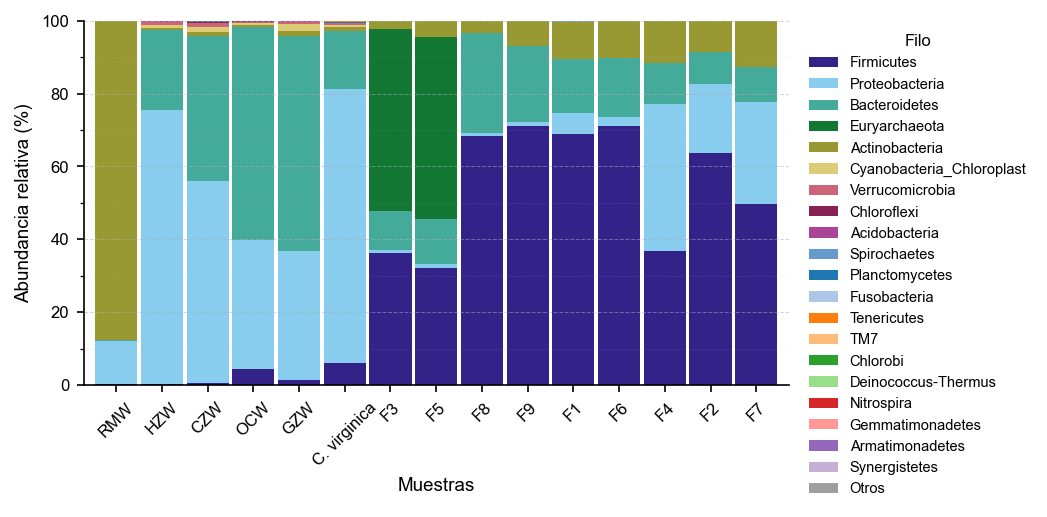

In [529]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ----- opcional: ordenar muestras por similitud si hay scipy -----
try:
    from scipy.spatial.distance import pdist
    from scipy.cluster.hierarchy import linkage, leaves_list
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False

# =========================
# 0) DataFrame de Filo
# =========================
# usa 18S si existe; si no, cae a 16S (como tenías)
try:
    df = df_all_18SF.copy()
except NameError:
    df = df_all_16SF.copy()  # <- tú habías puesto: df_all_18SF = df_all_16SF.copy()

# Si 'Filo' no está como columna, intenta recuperarlo del índice
if 'Filo' not in df.columns:
    if df.index.name == 'Filo':
        df = df.reset_index()
    else:
        df = df.reset_index()
        if 'Filo' not in df.columns:
            if 'index' in df.columns:
                df = df.rename(columns={'index': 'Filo'})
            else:
                raise KeyError("No se encontró la columna 'Filo' ni estaba como índice.")

# Arreglo de etiquetas conocidas
df['Filo'] = df['Filo'].replace({
    'Cryptista:nucl': 'Cryptista',
    'Cryptophyta:nucl': 'Cryptophyta'
})

# =========================
# 1) Filtrado y columnas de muestras
# =========================
filos_a_eliminar = ['Eukaryota_unclassified', 'Streptophyta', 'Cryptophyta:nucl']
df = df[~df['Filo'].isin(filos_a_eliminar)]

cols_muestras = [c for c in df.columns if c not in ['Filo', 'p-values']]
if 'SumaTotal' in cols_muestras:
    cols_muestras.remove('SumaTotal')

df[cols_muestras] = df[cols_muestras].apply(pd.to_numeric, errors='coerce').fillna(0)

# =========================
# 2) Agregación por Filo
# =========================
abund_por_filo = df.groupby('Filo')[cols_muestras].sum()

# =========================
# 3) Top 20 por ABUNDANCIA (descendente)
# =========================
N_TOP = 20
totales_filo = abund_por_filo.sum(axis=1).sort_values(ascending=False)
top20_filos = totales_filo.head(N_TOP).index.tolist()           # selección
orden_abund = abund_por_filo.loc[top20_filos].sum(axis=1)       # orden final
orden_abund = orden_abund.sort_values(ascending=False).index.tolist()

# =========================
# 4) Normalización correcta a % sobre el TOTAL por muestra
# =========================
total_por_muestra = abund_por_filo.sum(axis=0).replace(0, np.nan)

full_norm = (abund_por_filo.T
             .div(total_por_muestra, axis=0)
             .fillna(0) * 100)

top_norm = full_norm[orden_abund].copy()

# =========================
# 5) "Otros" = 100 - suma(top20) por muestra
# =========================
mat_norm = top_norm.copy()
mat_norm['Otros'] = (100 - top_norm.sum(axis=1)).clip(lower=0)

# =========================
# 6) (Opcional) Ordenar muestras por similitud (Bray–Curtis)
# =========================
if SCIPY_OK and mat_norm.shape[0] > 2:
    try:
        D = pdist(mat_norm.values, metric='braycurtis')
        Z = linkage(D, method='average')
        order_idx = leaves_list(Z)
        mat_norm = mat_norm.iloc[order_idx]
    except Exception:
        pass

# =========================
# 6.1) Reordenación manual: poner "C. virginica" antes de "F3"
# =========================
def mover_antes(lista, item, antes_de):
    if item in lista and antes_de in lista:
        lista = [x for x in lista if x != item]
        idx = lista.index(antes_de)
        lista.insert(idx, item)
    return lista

orden_x = list(mat_norm.index)

# Intenta reconocer la etiqueta de C. virginica con varias variantes comunes
aliases_cvir = ["C. virginica", "Crassostrea virginica", "C. virginica (promedio)"]
alias_cvir_presente = next((a for a in aliases_cvir if a in orden_x), None)

# Intenta reconocer F3 (por si en tu DF está como 'HecesP8' u otra variante)
aliases_f3 = ["F3", "HecesP8", "F-3"]
alias_f3_presente = next((a for a in aliases_f3 if a in orden_x), None)

if alias_cvir_presente and alias_f3_presente:
    orden_x = mover_antes(orden_x, alias_cvir_presente, alias_f3_presente)
    mat_norm = mat_norm.loc[orden_x]
# Si no encuentra las etiquetas, no hace nada y sigue el orden actual


# =========================
# 7) Estilo “journal-ready” y gráfico
# =========================
cols_plot = orden_abund + ['Otros']  # orden por abundancia global

mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,        # embebe fuentes
    "axes.linewidth": 0.8,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 7,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
})

tol = ["#332288","#88CCEE","#44AA99","#117733","#999933",
       "#DDCC77","#CC6677","#882255","#AA4499","#6699CC"]
tab20 = [plt.cm.tab20(i) for i in range(20)]
palette = (tol + tab20)[:len(cols_plot)-1] + ["#9E9E9E"]  # gris más claro para “Otros”
color_map = {g: c for g, c in zip(cols_plot, palette)}

fig, ax = plt.subplots(figsize=(7.09, 3.5))
mat_norm[cols_plot].plot(kind='bar', stacked=True, ax=ax,
                         color=[color_map[c] for c in cols_plot],
                         width=0.92, edgecolor="none")

ax.set_ylabel("Abundancia relativa (%)")
ax.set_xlabel("Muestras")
ax.set_ylim(0, 100)
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(20))
ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(10))
ax.grid(axis="y", which="major", linestyle="--", linewidth=0.5, alpha=0.5)
ax.grid(axis="y", which="minor", linestyle=":",  linewidth=0.35, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", rotation=45)

ax.legend(title="Filo",
          bbox_to_anchor=(1.01, 1), loc='upper left',
          frameon=False, ncol=1, title_fontsize=8)

fig.tight_layout()
fig.savefig("fig_filos_top_abundancia.tiff", dpi=600,
            pil_kwargs={'compression': 'tiff_lzw'})
fig.savefig("fig_filos_top_abundancia.pdf")
plt.show()


In [530]:
print(df_all_16SG.info())
df_all_16SG = df_all_16SG[['p-values', 'Level_6', 'CV: mean rel. freq. (%)', 'HecesP6: rel. freq. (%)',
                            'HecesP7: rel. freq. (%)', 'HecesP8: rel. freq. (%)', 'HecesP9: rel. freq. (%)', 
                            'HecesP10: rel. freq. (%)', 'HecesP11: rel. freq. (%)', 'HecesP12: rel. freq. (%)', 
                            'HecesP13: rel. freq. (%)', 'HecesP14: rel. freq. (%)', 'AguaP1: rel. freq. (%)', 
                            'AguaP2: rel. freq. (%)', 'AguaP3: rel. freq. (%)', 'AguaP4: rel. freq. (%)', 
                            'AguaP5: rel. freq. (%)']]
print(df_all_16SG.info())
display(df_all_16SG.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 89 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Level_1                                     541 non-null    object 
 1   Level_2                                     541 non-null    object 
 2   Level_3                                     541 non-null    object 
 3   Level_4                                     541 non-null    object 
 4   Level_5                                     541 non-null    object 
 5   Level_6                                     541 non-null    object 
 6   p-values                                    541 non-null    float64
 7   p-values (corrected)                        541 non-null    float64
 8   Effect size                                 541 non-null    float64
 9   Note                                        0 non-null      float64
 10  CV: mean rel. 

,p-values,Level_6,CV: mean rel. freq. (%),HecesP6: rel. freq. (%),HecesP7: rel. freq. (%),HecesP8: rel. freq. (%),HecesP9: rel. freq. (%),HecesP10: rel. freq. (%),HecesP11: rel. freq. (%),HecesP12: rel. freq. (%),HecesP13: rel. freq. (%),HecesP14: rel. freq. (%),AguaP1: rel. freq. (%),AguaP2: rel. freq. (%),AguaP3: rel. freq. (%),AguaP4: rel. freq. (%),AguaP5: rel. freq. (%)
0,1.781406e-01,Methanobrevibacter,0.000000,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000
1,0.000000e+00,Actinomyces,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,0.0,0.000000,0.0,0.0,0.000000
2,5.517364e-65,Pseudoalteromonas,99.977827,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000
3,2.048128e-53,Rheinheimera,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,99.166667,100.0,100.0,99.641577
4,2.078080e-15,Barnesiella,0.856706,37.662338,73.333333,55.831266,53.278689,64.285714,57.264957,61.904762,55.681818,56.470588,0.0,0.000000,0.0,0.0,0.000000


In [531]:
df_all_16SG = df_all_16SG.rename(columns={'Level_6': 'Género',
                            'CV: mean rel. freq. (%)': 'C. virginica',
                            'HecesP6: rel. freq. (%)': 'F1',
                            'HecesP7: rel. freq. (%)': 'F2',
                            'HecesP8: rel. freq. (%)': 'F3',
                            'HecesP9: rel. freq. (%)': 'F4',
                            'HecesP10: rel. freq. (%)': 'F5',
                            'HecesP11: rel. freq. (%)': 'F6',
                            'HecesP12: rel. freq. (%)': 'F7',
                            'HecesP13: rel. freq. (%)': 'F8',
                            'HecesP14: rel. freq. (%)': 'F9',
                            'AguaP1: rel. freq. (%)' : 'OCW', 
                            'AguaP2: rel. freq. (%)' : 'HZW', 
                            'AguaP3: rel. freq. (%)' : 'GZW',
                            'AguaP4: rel. freq. (%)' : 'RMW',
                            'AguaP5: rel. freq. (%)' : 'CZW'})
print(df_all_16SG.info())
display(df_all_16SG.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      541 non-null    float64
 1   Género        541 non-null    object 
 2   C. virginica  541 non-null    float64
 3   F1            541 non-null    float64
 4   F2            541 non-null    float64
 5   F3            541 non-null    float64
 6   F4            541 non-null    float64
 7   F5            541 non-null    float64
 8   F6            541 non-null    float64
 9   F7            541 non-null    float64
 10  F8            541 non-null    float64
 11  F9            541 non-null    float64
 12  OCW           541 non-null    float64
 13  HZW           541 non-null    float64
 14  GZW           541 non-null    float64
 15  RMW           541 non-null    float64
 16  CZW           541 non-null    float64
dtypes: float64(16), object(1)
memory usage: 72.0+ KB
None


,p-values,Género,C. virginica,F1,F2,F3,F4,F5,F6,F7,F8,F9,OCW,HZW,GZW,RMW,CZW
0,1.781406e-01,Methanobrevibacter,0.000000,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000
1,0.000000e+00,Actinomyces,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,0.0,0.000000,0.0,0.0,0.000000
2,5.517364e-65,Pseudoalteromonas,99.977827,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000
3,2.048128e-53,Rheinheimera,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,99.166667,100.0,100.0,99.641577
4,2.078080e-15,Barnesiella,0.856706,37.662338,73.333333,55.831266,53.278689,64.285714,57.264957,61.904762,55.681818,56.470588,0.0,0.000000,0.0,0.0,0.000000


In [532]:
df_all_16G = pd.concat([df_all_16SG.head(20)])
df_all_16G = df_all_16G.sort_index()
print(df_all_16G.info())
display(df_all_16G.head(20))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      20 non-null     float64
 1   Género        20 non-null     object 
 2   C. virginica  20 non-null     float64
 3   F1            20 non-null     float64
 4   F2            20 non-null     float64
 5   F3            20 non-null     float64
 6   F4            20 non-null     float64
 7   F5            20 non-null     float64
 8   F6            20 non-null     float64
 9   F7            20 non-null     float64
 10  F8            20 non-null     float64
 11  F9            20 non-null     float64
 12  OCW           20 non-null     float64
 13  HZW           20 non-null     float64
 14  GZW           20 non-null     float64
 15  RMW           20 non-null     float64
 16  CZW           20 non-null     float64
dtypes: float64(16), object(1)
memory usage: 2.8+ KB
None


,p-values,Género,C. virginica,F1,F2,F3,F4,F5,F6,F7,F8,F9,OCW,HZW,GZW,RMW,CZW
0,1.781406e-01,Methanobrevibacter,0.000000,0.000000,0.000000,100.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
1,0.000000e+00,Actinomyces,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,0.000000,0.000000,0.000000,0.0,0.000000
2,5.517364e-65,Pseudoalteromonas,99.977827,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
3,2.048128e-53,Rheinheimera,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,99.166667,100.000000,100.0,99.641577
4,2.078080e-15,Barnesiella,0.856706,37.662338,73.333333,55.831266,53.278689,64.285714,57.264957,61.904762,55.681818,56.470588,0.000000,0.000000,0.000000,0.0,0.000000
5,4.240542e-11,Fusibacter,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,75.000000,50.000000,0.000000,0.0,71.428571
6,3.584164e-10,Clostridium_XI,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,66.666667,100.000000,100.000000,0.0,91.666667
7,7.566177e-10,Algoriphagus,99.207632,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,95.238095,100.000000,96.428571,0.0,100.000000
8,8.716026e-10,Exiguobacterium,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,100.000000,100.000000,0.0,100.000000
9,1.245056e-09,Bacillariophyta,96.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,86.458333,96.511628,99.506173,0.0,96.690307


In [533]:
# Quitar columnas 'object'
columnas_muestras_16S = df_all_16SG.columns.difference(['Género', 'p-values'])

# Nueva columna con la suma total de abundancia relativa
df_all_16SG['SumaTotal'] = df_all_16SG[columnas_muestras_16S].sum(axis=1)

# Ordenar de mayor a menor
df_all_16SG = df_all_16SG.sort_values(by='SumaTotal', ascending=False)

# Eliminar la columna auxiliar
df_all_16SG = df_all_16SG.drop(columns='SumaTotal')

print(df_all_16SG.info())

<class 'pandas.core.frame.DataFrame'>
Index: 541 entries, 339 to 308
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      541 non-null    float64
 1   Género        541 non-null    object 
 2   C. virginica  541 non-null    float64
 3   F1            541 non-null    float64
 4   F2            541 non-null    float64
 5   F3            541 non-null    float64
 6   F4            541 non-null    float64
 7   F5            541 non-null    float64
 8   F6            541 non-null    float64
 9   F7            541 non-null    float64
 10  F8            541 non-null    float64
 11  F9            541 non-null    float64
 12  OCW           541 non-null    float64
 13  HZW           541 non-null    float64
 14  GZW           541 non-null    float64
 15  RMW           541 non-null    float64
 16  CZW           541 non-null    float64
dtypes: float64(16), object(1)
memory usage: 76.1+ KB
None


In [534]:
columnas_muestras = [
    col for col in df_all_16SG.columns
    if col not in ['p-values', 'Género']  # agrega aquí otras columnas no numéricas si las hay
]

# Calcular la suma total por género
df_all_16SG['SumaTotal'] = df_all_16SG[columnas_muestras].sum(axis=1)


# Seleccionar los 20 géneros con mayor suma
df_top20g = df_all_16SG.nlargest(20, 'SumaTotal')
df_top20g = df_top20g.drop(columns='SumaTotal')
print(df_top20g.info())

<class 'pandas.core.frame.DataFrame'>
Index: 20 entries, 339 to 98
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p-values      20 non-null     float64
 1   Género        20 non-null     object 
 2   C. virginica  20 non-null     float64
 3   F1            20 non-null     float64
 4   F2            20 non-null     float64
 5   F3            20 non-null     float64
 6   F4            20 non-null     float64
 7   F5            20 non-null     float64
 8   F6            20 non-null     float64
 9   F7            20 non-null     float64
 10  F8            20 non-null     float64
 11  F9            20 non-null     float64
 12  OCW           20 non-null     float64
 13  HZW           20 non-null     float64
 14  GZW           20 non-null     float64
 15  RMW           20 non-null     float64
 16  CZW           20 non-null     float64
dtypes: float64(16), object(1)
memory usage: 2.8+ KB
None


<>:41: SyntaxWarning: invalid escape sequence '\m'
<>:41: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\1739942697.py:41: SyntaxWarning: invalid escape sequence '\m'
  plt.title("Comparative Genus composition in fecal samples, $\mathit{C.\ virginica}$ and water samples")
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\1739942697.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_top20_genus["Otros"] = (100 - df_top20_genus.sum(axis=1)).clip(lower=0)
C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\1739942697.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.g

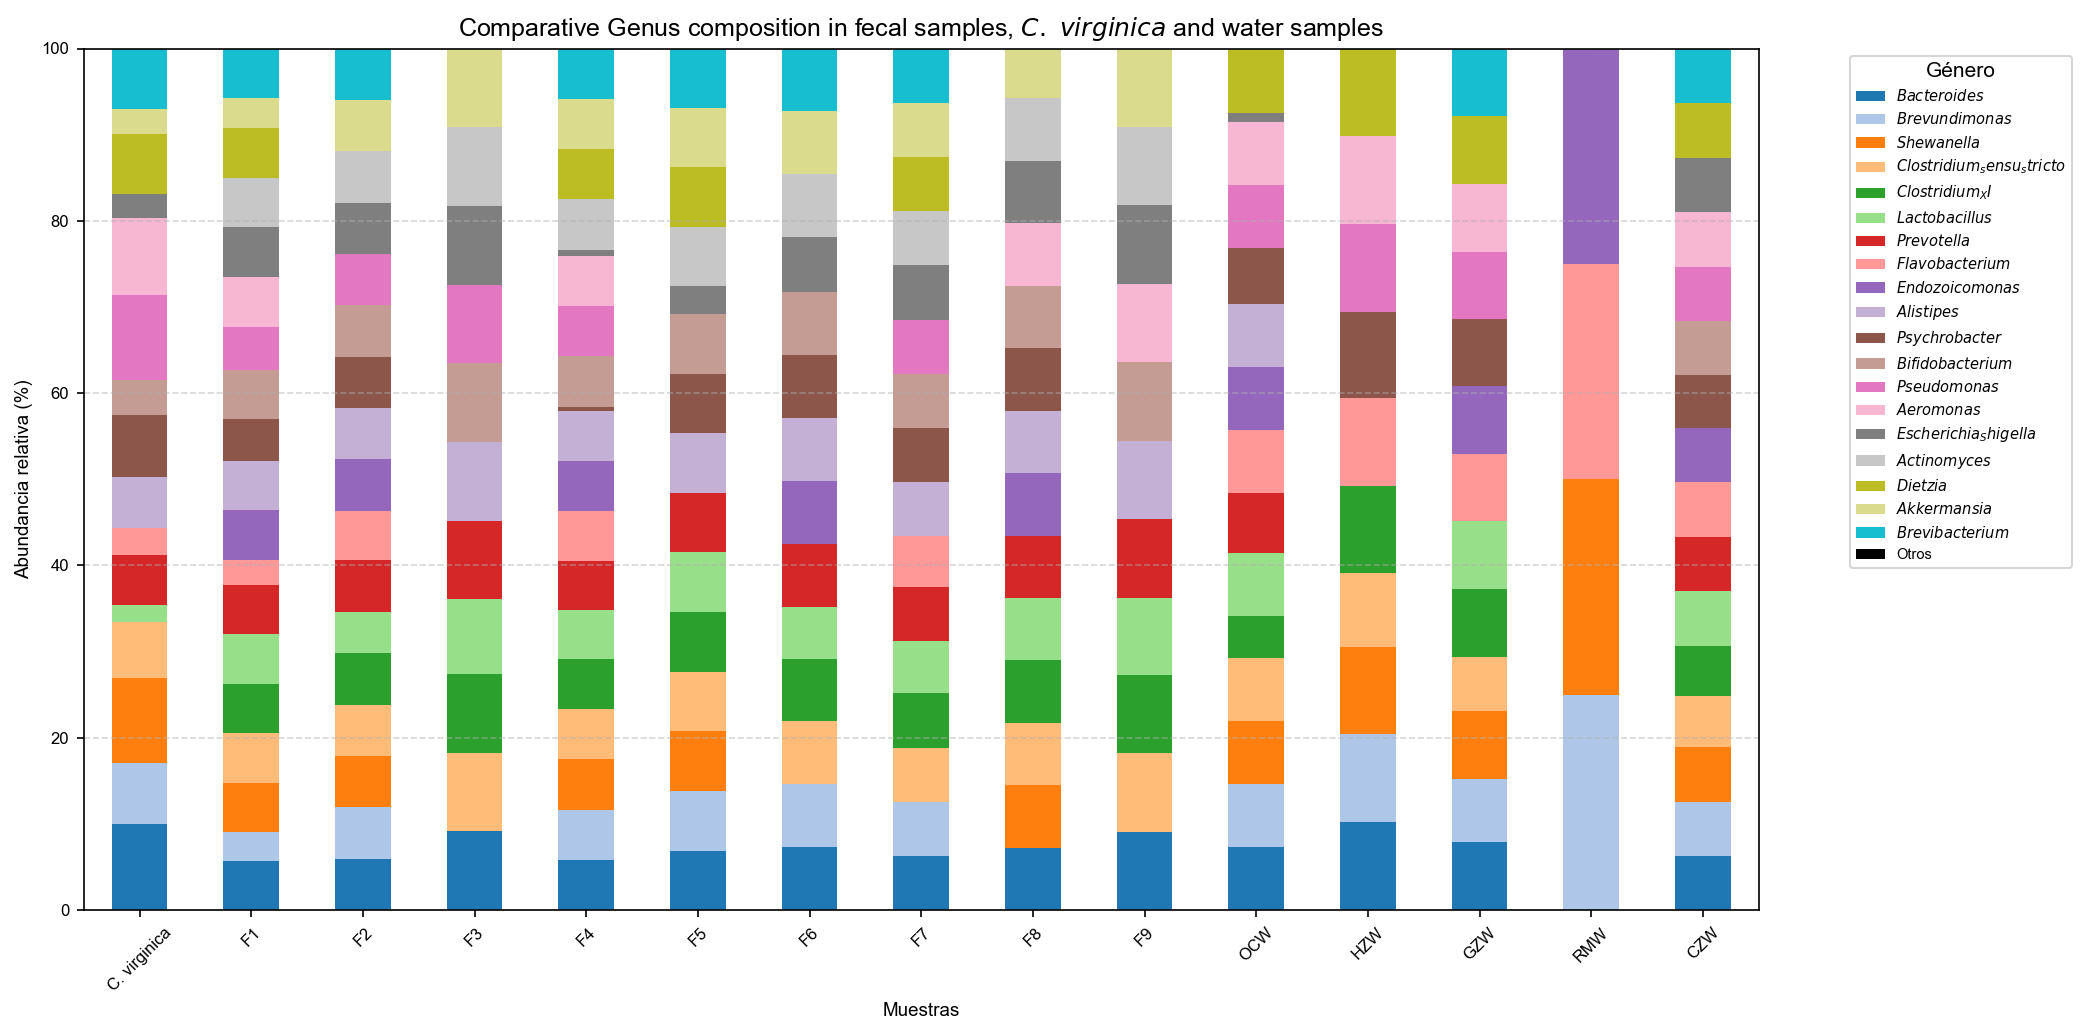

In [535]:
filos_a_eliminar_7 = ['unknown_unclassified', 'TM7_genus_incertae_sedis']
df_top20g = df_top20g[~df_top20g['Género'].isin(filos_a_eliminar_7)]

# Asegurar que 'Género' sea índice (solo una vez)
df_top20g.set_index('Género', inplace=True)

# Eliminar columna 'p-values' antes de transponer
df_top20g_T = df_top20g.drop(columns='p-values').T

# Normalizar por filas para que sumen 100%
df_top20g_norm = df_top20g_T.div(df_top20g_T.sum(axis=1), axis=0) * 100

# Identificar los 20 géneros más abundantes
top20_genus = df_top20g_norm.sum(axis=0).sort_values(ascending=False).head(20).index

# Filtrar solo esos géneros
df_top20_genus = df_top20g_norm[top20_genus]

# Agregar columna "Otros"
df_top20_genus["Otros"] = (100 - df_top20_genus.sum(axis=1)).clip(lower=0)

# Crear lista de colores: 20 de tab20 + negro para 'Otros'
cmap = get_cmap('tab20')
colors = [cmap(i) for i in range(len(top20_genus))] + ['black']

# Graficar
ax = df_top20_genus.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    color=colors
)

# Personalización de leyenda con etiquetas en cursiva (menos "Otros")
handles, labels = ax.get_legend_handles_labels()
labels_italic = [f"$\\it{{{label}}}$" if label != "Otros" else label for label in labels]
ax.legend(handles, labels_italic, title="Género", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.ylabel("Abundancia relativa (%)")
plt.xlabel("Muestras")
plt.title("Comparative Genus composition in fecal samples, $\mathit{C.\ virginica}$ and water samples")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

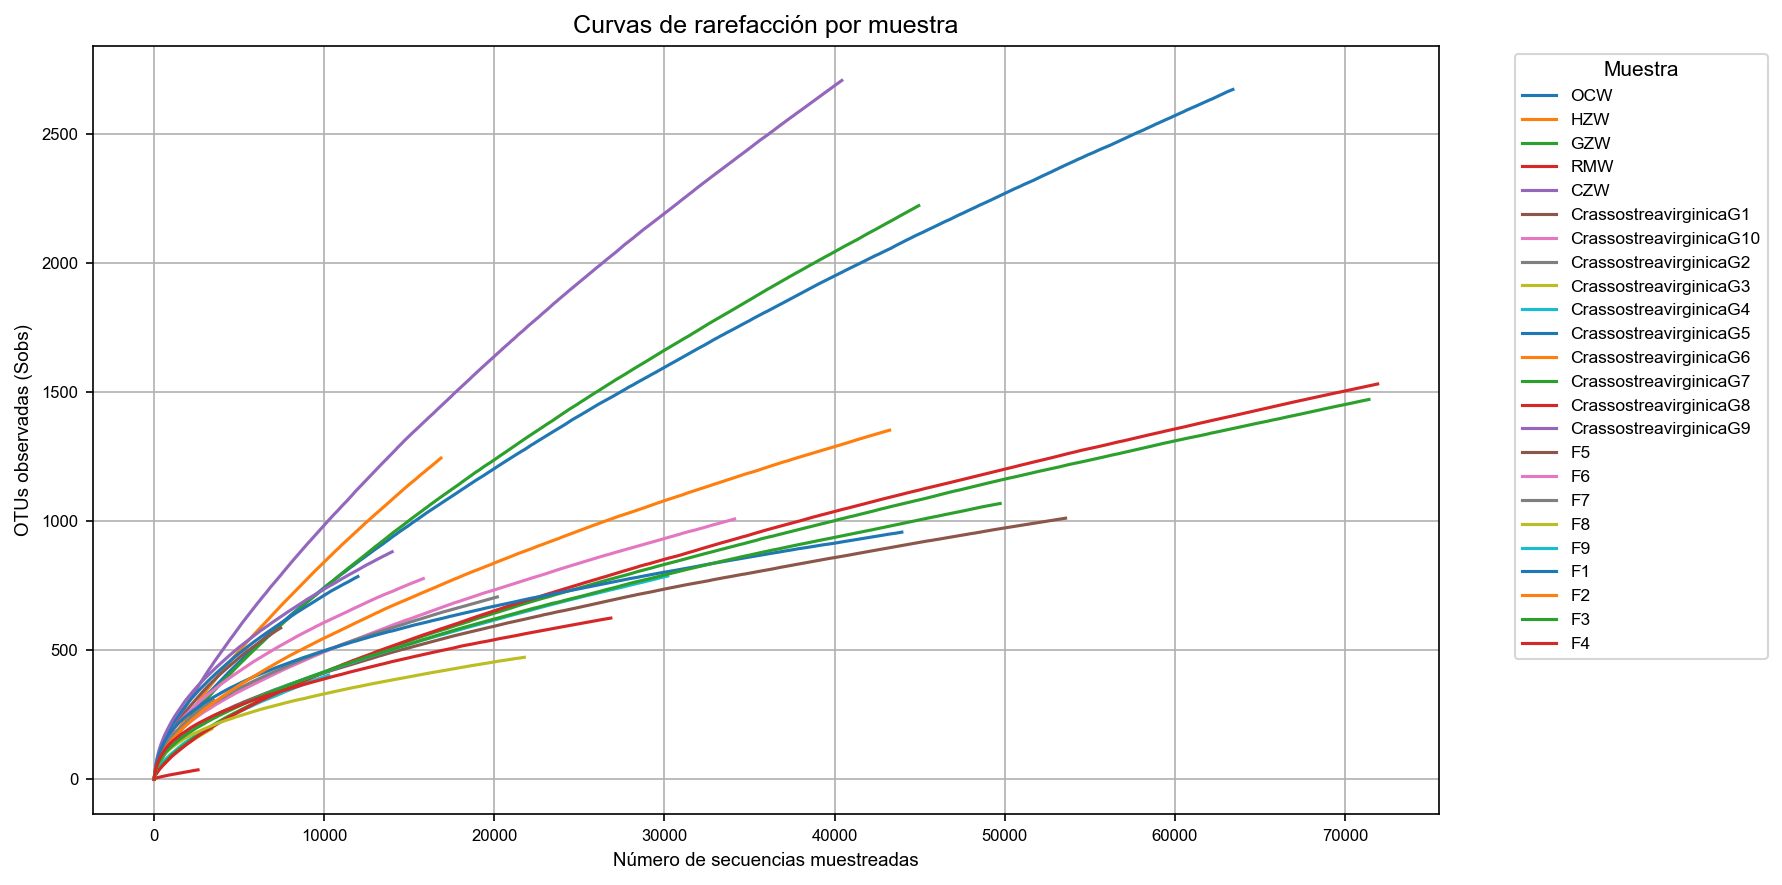

In [536]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar el archivo
archivo = "final.opti_mcc.groups.rarefaction"
df = pd.read_csv(archivo, sep='\t')

# Extraer columnas de rarefacción (las que comienzan con "0.03-")
muestras = [col for col in df.columns if col.startswith("0.03-")]

# Diccionario de reemplazo de nombres
renombres = {
    "AguaP1": "OCW",
    "AguaP2": "HZW",
    "AguaP3": "GZW",
    "AguaP4": "RMW",
    "AguaP5": "CZW",
    "HecesP6": "F1",
    "HecesP7": "F2",
    "HecesP8": "F3",
    "HecesP9": "F4",
    "HecesP10": "F5",
    "HecesP11": "F6",
    "HecesP12": "F7",
    "HecesP13": "F8",
    "HecesP14": "F9"
}

# Iniciar la gráfica
plt.figure(figsize=(12, 6))

# Graficar cada muestra con nombre renombrado
for muestra in muestras:
    nombre_original = muestra.replace("0.03-", "")
    nombre_nuevo = renombres.get(nombre_original, nombre_original)  # Usa renombre si existe
    plt.plot(df['numsampled'], df[muestra], label=nombre_nuevo)

# Personalización
plt.xlabel('Número de secuencias muestreadas')
plt.ylabel('OTUs observadas (Sobs)')
plt.title('Curvas de rarefacción por muestra')
plt.legend(title='Muestra', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.grid(True)
plt.show()


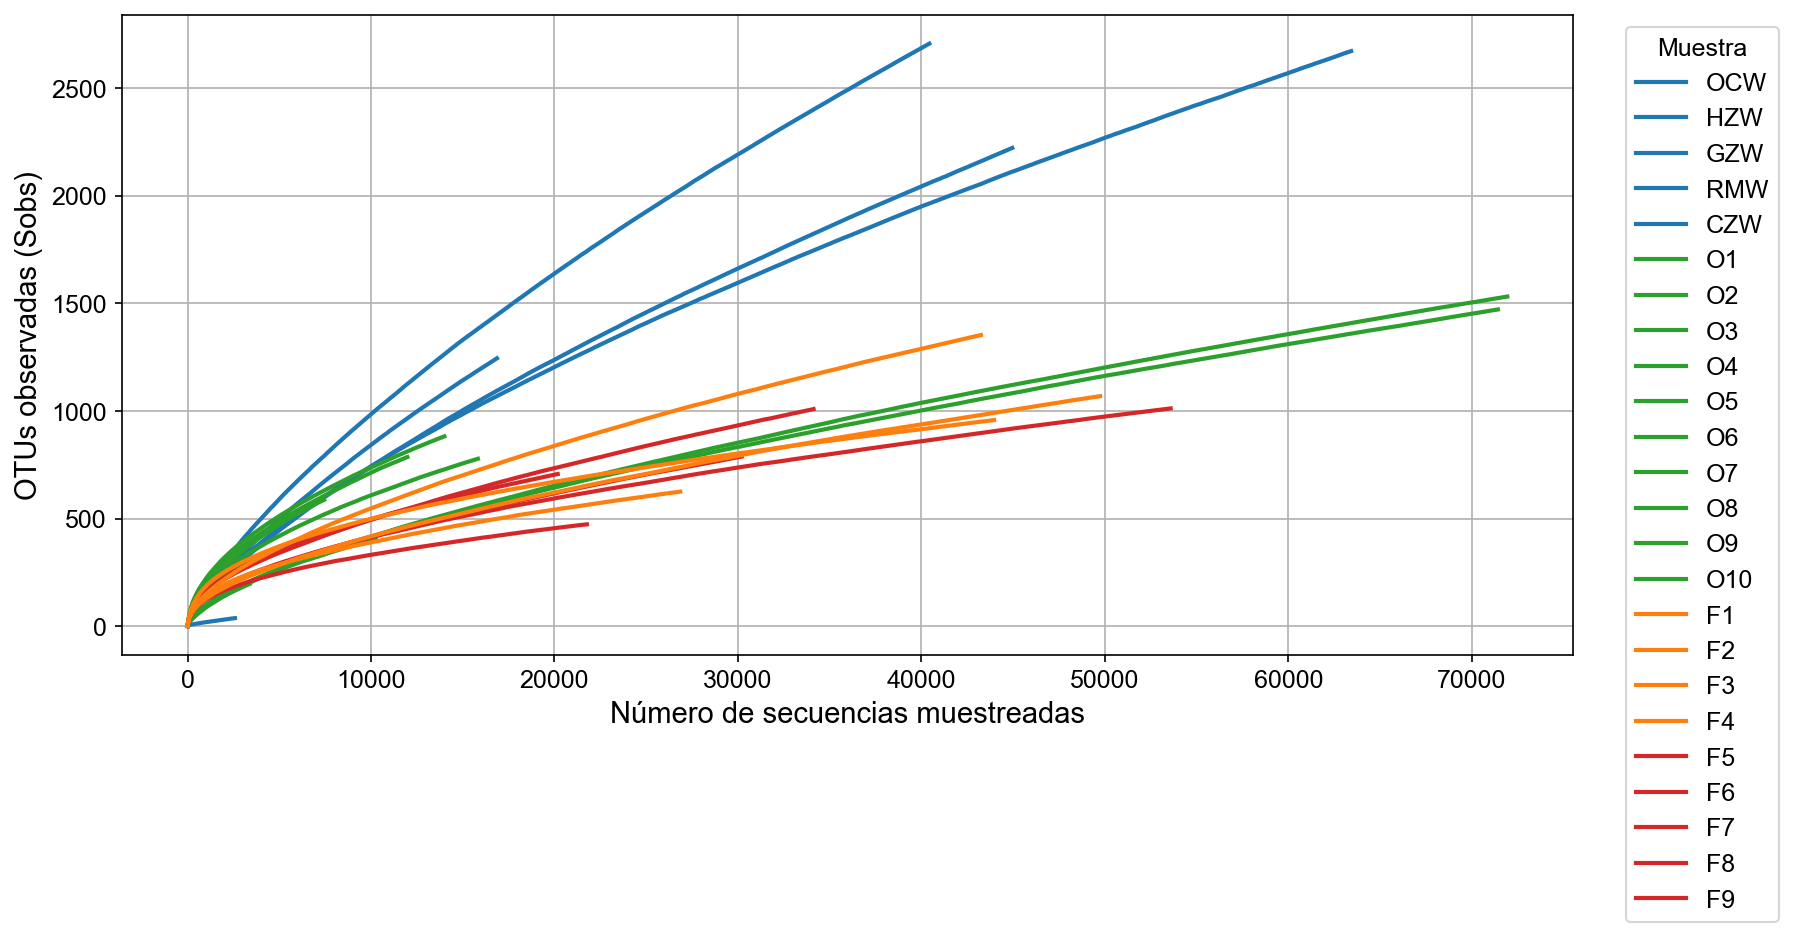

In [537]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar el archivo
archivo = "final.opti_mcc.groups.rarefaction"
df = pd.read_csv(archivo, sep='\t')

# Extraer columnas de rarefacción (las que comienzan con "0.03-")
muestras = [col for col in df.columns if col.startswith("0.03-")]

# Diccionario de reemplazo de nombres
renombres = {
    "AguaP1": "OCW",
    "AguaP2": "HZW",
    "AguaP3": "GZW",
    "AguaP4": "RMW",
    "AguaP5": "CZW",
    "CrassostreavirginicaG1": "O1",
    "CrassostreavirginicaG2": "O2",
    "CrassostreavirginicaG3": "O3",
    "CrassostreavirginicaG4": "O4",
    "CrassostreavirginicaG5": "O5",
    "CrassostreavirginicaG6": "O6",
    "CrassostreavirginicaG7": "O7",
    "CrassostreavirginicaG8": "O8",
    "CrassostreavirginicaG9": "O9",
    "CrassostreavirginicaG10": "O10",
    "HecesP6": "F1",
    "HecesP7": "F2",
    "HecesP8": "F3",
    "HecesP9": "F4",
    "HecesP10": "F5",
    "HecesP11": "F6",
    "HecesP12": "F7",
    "HecesP13": "F8",
    "HecesP14": "F9"
}

# Asignar colores por tipo de muestra
colores = {
    "OCW": "#1f77b4",  # azul agua
    "HZW": "#1f77b4",
    "GZW": "#1f77b4",
    "RMW": "#1f77b4",
    "CZW": "#1f77b4",
    "O1": "#2ca02c", "O2": "#2ca02c", "O3": "#2ca02c", "O4": "#2ca02c",
    "O5": "#2ca02c", "O6": "#2ca02c", "O7": "#2ca02c", "O8": "#2ca02c",
    "O9": "#2ca02c", "O10": "#2ca02c",
    "F1": "#ff7f0e", "F2": "#ff7f0e", "F3": "#ff7f0e", "F4": "#ff7f0e",
    "F5": "#d62728", "F6": "#d62728", "F7": "#d62728",
    "F8": "#d62728", "F9": "#d62728"
}

# Orden manual para leyenda
orden_leyenda = (
    ["OCW", "HZW", "GZW", "RMW", "CZW"] +
    [f"O{i}" for i in range(1, 11)] +
    [f"F{i}" for i in range(1, 10)]
)

# Iniciar la gráfica
plt.figure(figsize=(12, 6))

# Graficar cada muestra
for muestra in muestras:
    nombre_original = muestra.replace("0.03-", "")
    nombre_nuevo = renombres.get(nombre_original, nombre_original)
    color = colores.get(nombre_nuevo, "#7f7f7f")

    plt.plot(df['numsampled'], df[muestra],
             label=nombre_nuevo,
             linewidth=2,
             color=color)

# Personalización
plt.xlabel('Número de secuencias muestreadas', fontsize=14)
plt.ylabel('OTUs observadas (Sobs)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)

# Ordenar leyenda según 'orden_leyenda'
handles, labels = plt.gca().get_legend_handles_labels()
orden_indices = [labels.index(l) for l in orden_leyenda if l in labels]
handles = [handles[i] for i in orden_indices]
labels = [labels[i] for i in orden_indices]

plt.legend(handles, labels, title='Muestra',
           bbox_to_anchor=(1.15, 1), loc='upper right',
           fontsize=12, ncol=1, title_fontsize=12)

plt.tight_layout()
plt.savefig("curvas_rarefaccion.pdf", format="pdf", dpi=300)
plt.show()






C:\Users\Mijail\AppData\Local\Temp\ipykernel_27392\2544736790.py:74: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab20')


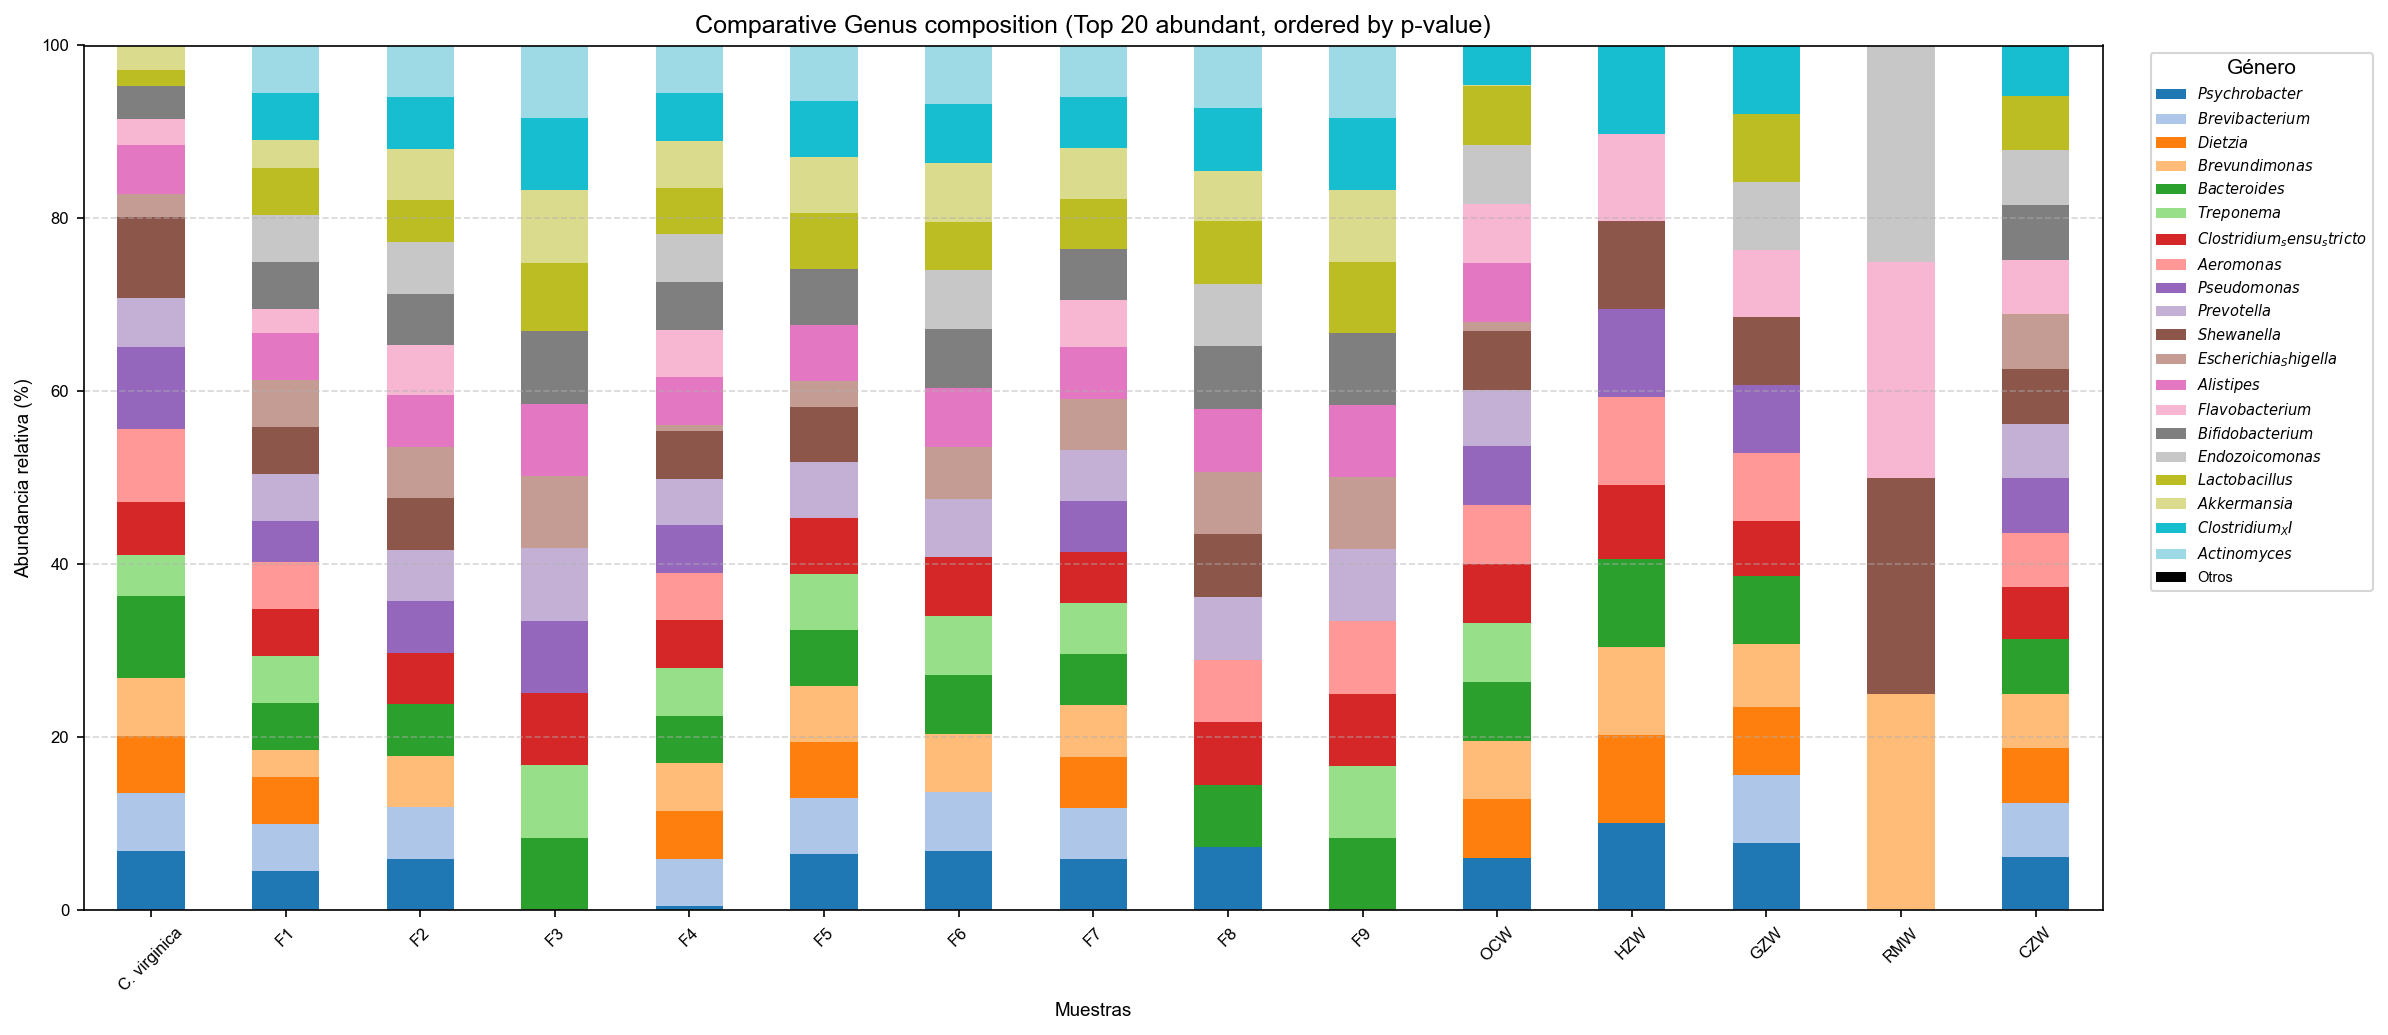

In [538]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap

# =========================
# Configuración de entrada
# =========================
# df_all_16SG debe tener columnas:
#  - 'Género' (str)
#  - 'p-values' (float)
#  - columnas de muestras con abundancia relativa (numéricas)

# -------- 1) Copia y limpieza básica ----------
df = df_all_16SG.copy()

# Filtra géneros no deseados
generos_a_eliminar = ['unknown_unclassified', 'TM7_genus_incertae_sedis']
df = df[~df['Género'].isin(generos_a_eliminar)]

# Columnas de abundancia (todas menos 'Género' y 'p-values')
cols_abund = [c for c in df.columns if c not in ['Género', 'p-values']]

# Asegura numérico y NaN->0
df[cols_abund] = df[cols_abund].apply(pd.to_numeric, errors='coerce').fillna(0)

# -------- 2) Top 20 más abundantes ----------
# Suma total por género (en todas las muestras)
df['SumaTotal'] = df[cols_abund].sum(axis=1)

# Toma los 20 géneros más abundantes (1 fila por género)
df_top20 = (
    df.sort_values('SumaTotal', ascending=False)
      .drop_duplicates(subset='Género', keep='first')
      .head(20)
      .copy()
)

# -------- 3) Ordenar esos 20 por p-value ----------
if 'p-values' in df_top20.columns:
    df_top20 = df_top20.sort_values('p-values', ascending=False)

# Orden final de géneros (abundantes y con p-value ascendente)
top20_generos = df_top20['Género'].tolist()

# -------- 4) Agrupar abundancias y preparar matriz muestra×género ----------
df_grouped = df.groupby('Género')[cols_abund].sum()

# Mantener solo top20 y en el orden deseado
df_top = df_grouped.loc[[g for g in top20_generos if g in df_grouped.index]]

# Transponer para tener filas=muestras, columnas=géneros
df_norm = df_top.T

# Normaliza por muestra a 100%
df_norm = df_norm.div(df_norm.sum(axis=1), axis=0).fillna(0) * 100

# -------- 5) Calcular "Otros" (todo lo fuera del top20) ----------
otros = df_grouped.drop(index=[g for g in df_grouped.index if g in top20_generos], errors='ignore')
if not otros.empty:
    otros_norm = otros.T
    otros_norm = otros_norm.div(otros_norm.sum(axis=1), axis=0).fillna(0) * 100
    df_norm['Otros'] = otros_norm.sum(axis=1)
else:
    df_norm['Otros'] = 0.0

# -------- 6) Asegurar que no exista 'SumaTotal' como muestra ----------
if 'SumaTotal' in df_norm.index:
    df_norm = df_norm.drop(index='SumaTotal')
if 'SumaTotal' in df_norm.columns:
    df_norm = df_norm.drop(columns='SumaTotal')

# -------- 7) Graficar ----------
# Colores: 20 de tab20 + negro para "Otros"
cmap = get_cmap('tab20')
colors = [cmap(i) for i in range(len(top20_generos))] + ['black']

ax = df_norm[top20_generos + ['Otros']].plot(
    kind='bar', stacked=True, figsize=(16, 7), color=colors
)

# Leyenda en cursiva para géneros (excepto "Otros")
handles, labels = ax.get_legend_handles_labels()
labels_italic = [f"$\\it{{{lbl}}}$" if lbl != "Otros" else lbl for lbl in labels]
ax.legend(handles, labels_italic, title="Género",
          bbox_to_anchor=(1.02, 1), loc='upper left')

plt.ylabel("Abundancia relativa (%)")
plt.xlabel("Muestras")
plt.title("Comparative Genus composition (Top 20 abundant, ordered by p-value)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


Cobertura mínima: 0.549
Cobertura mediana: 0.788


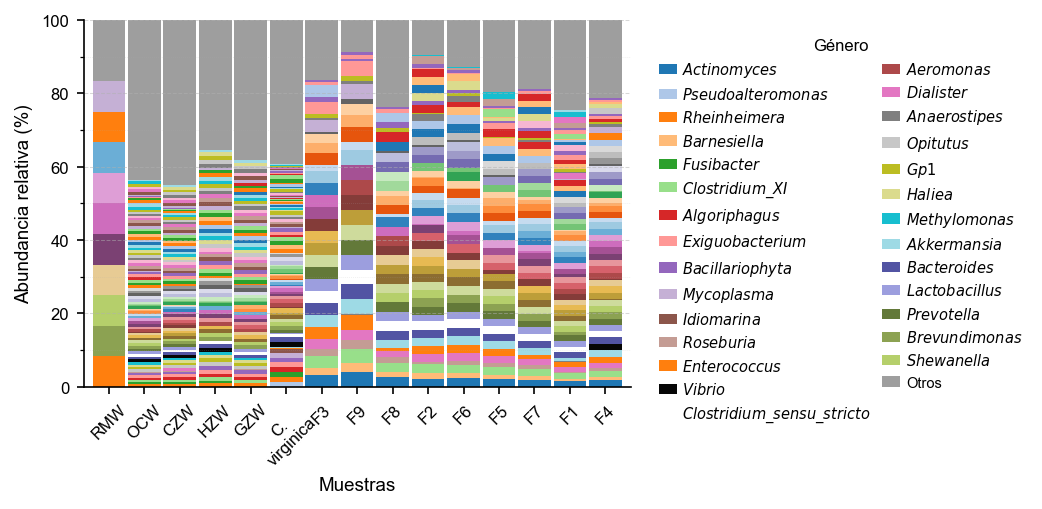

In [539]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import re
from textwrap import fill

# ===== opcional: ordenar muestras por similitud =====
try:
    from scipy.spatial.distance import pdist
    from scipy.cluster.hierarchy import linkage, leaves_list
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False

# =========================
# 1) Copia y limpieza básica
# =========================
df = df_all_16SG.copy()  # requiere: 'Género', 'p-values' (si existe) y columnas de muestras

# Filtra géneros no deseados
generos_a_eliminar = [
    'unknown_unclassified',
    'TM7_genus_incertae_sedis',
    'Erysipelotrichaceae_incertae_sedis'
]
df = df[~df['Género'].isin(generos_a_eliminar)]

# (opcional) normalizaciones de etiqueta comunes en 16S
df['Género'] = df['Género'].replace({
    'Escherichia-Shigella': 'Escherichia/Shigella',
})

# Columnas de abundancia
cols_abund = [c for c in df.columns if c not in ['Género', 'p-values']]
if 'SumaTotal' in cols_abund:
    cols_abund.remove('SumaTotal')
df[cols_abund] = df[cols_abund].apply(pd.to_numeric, errors='coerce').fillna(0)

# =========================
# 2) Agregación por género (abundancias y p-values)
# =========================
abund_por_gen = df.groupby('Género')[cols_abund].sum()
pval_por_gen = df.groupby('Género')['p-values'].min() if 'p-values' in df.columns else pd.Series(index=abund_por_gen.index, dtype=float)

# =========================
# 3) Top por p-value (ASC) + ampliar por ABUNDANCIA hasta cubrir cada muestra
# =========================
COVERAGE_TARGET = 0.85   # 85% por muestra (ajústalo 0.80–0.95)
MAX_GENEROS      = 120   # tope de seguridad
GENERO_FORZADO   = "Vibrio"

# 3.1 Selección base: p-value ascendente (o abundancia si no hay p-values)
if pval_por_gen.notna().any():
    base_sel = pval_por_gen.sort_values(ascending=True).head(20).index.tolist()
else:
    base_sel = abund_por_gen.sum(axis=1).sort_values(ascending=False).head(20).index.tolist()

# 3.2 Forzar Vibrio si aparece con >0 en alguna muestra
presente_vibrio = (GENERO_FORZADO in abund_por_gen.index) and (abund_por_gen.loc[GENERO_FORZADO] > 0).any()
if presente_vibrio and GENERO_FORZADO not in base_sel:
    base_sel.append(GENERO_FORZADO)

# 3.3 Normaliza por muestra (proporciones, no %) para calcular cobertura
tot_por_muestra = abund_por_gen.sum(axis=0).replace(0, np.nan)
rel = abund_por_gen.div(tot_por_muestra, axis=1).fillna(0.0)

def cobertura_actual(sel):
    if not sel:
        return pd.Series(0.0, index=rel.columns)
    return rel.loc[sel].sum(axis=0).clip(upper=1.0)

# 3.4 Agrega géneros por abundancia global hasta alcanzar COVERAGE_TARGET en TODAS las muestras
orden_abund = abund_por_gen.sum(axis=1).sort_values(ascending=False).index.tolist()
seleccion = list(base_sel)  # respetaremos su orden (p-value primero)

cov = cobertura_actual(seleccion)
i = 0
while (cov.min() < COVERAGE_TARGET) and (len(seleccion) < MAX_GENEROS):
    # candidato: siguiente más abundante global que no esté ya seleccionado
    while i < len(orden_abund) and orden_abund[i] in seleccion:
        i += 1
    if i >= len(orden_abund):
        break
    seleccion.append(orden_abund[i])
    cov = cobertura_actual(seleccion)
    i += 1

# 3.5 Orden final para la leyenda:
#     - Primero los de p-value (en su orden)
#     - Luego los añadidos por abundancia (ordenados por abundancia global)
anadidos = [g for g in seleccion if g not in base_sel]
anadidos = abund_por_gen.loc[anadidos].sum(axis=1).sort_values(ascending=False).index.tolist()
seleccion_ordenada = base_sel + anadidos

# (opcional) imprime diagnóstico de cobertura
cov_diag = cobertura_actual(seleccion_ordenada)
print("Cobertura mínima:", float(cov_diag.min().round(3)))
print("Cobertura mediana:", float(cov_diag.median().round(3)))


# =========================
# 4) Normalización a % sobre el TOTAL por muestra (complemento para "Otros")
# =========================
total_por_muestra = abund_por_gen.sum(axis=0).replace(0, np.nan)

full_norm = (abund_por_gen.T
             .div(total_por_muestra, axis=0)
             .fillna(0) * 100)

top_norm = full_norm[seleccion_ordenada].copy()

otros_pct = (100 - top_norm.sum(axis=1)).clip(lower=0)
mat_norm = top_norm.copy()
mat_norm['Otros'] = otros_pct

# ===== (opcional) Ordenar muestras por similitud =====
if SCIPY_OK and mat_norm.shape[0] > 2:
    try:
        D = pdist(mat_norm.values, metric='braycurtis')
        Z = linkage(D, method='average')
        order_idx = leaves_list(Z)
        mat_norm = mat_norm.iloc[order_idx]
    except Exception:
        pass

# =========================
# 4.1) Reordenación manual del eje X: poner C. virginica (o O1..O10) antes de F3
# =========================
def move_group_before(seq, group_labels, before_label):
    """Mueve el conjunto 'group_labels' (en su orden original) justo antes de 'before_label'."""
    # preserva el orden interno del grupo según aparece en 'seq'
    group_in_order = [x for x in seq if x in group_labels]
    if not group_in_order or before_label not in seq:
        return seq
    seq_new = [x for x in seq if x not in group_in_order]
    idx = seq_new.index(before_label)
    # insertamos en orden (de atrás hacia adelante para mantener posiciones)
    for x in reversed(group_in_order):
        seq_new.insert(idx, x)
    return seq_new

orden_x = list(mat_norm.index)

# Aliases comunes
aliases_cvir = ["C. virginica", "Crassostrea virginica", "C. virginica (promedio)"]
before_aliases = ["F3", "HecesP8", "F-3"]  # posibles nombres para F3

# ¿Cuál 'F3' existe?
before = next((a for a in before_aliases if a in orden_x), None)

# ¿Existe una muestra única llamada "C. virginica"?
targets = [a for a in aliases_cvir if a in orden_x]

# Si no hay "C. virginica", intentamos mover el bloque de O1..O10
if not targets:
    # Detecta muestras tipo O1..O10 si están presentes en el eje
    oysters = [x for x in orden_x if re.fullmatch(r"O\d+", str(x))]
    if oysters:
        targets = oysters  # mover todo el bloque de ostiones

# Aplica el movimiento si hay referencia 'before' válida
if before and targets:
    orden_x = move_group_before(orden_x, targets, before)
    mat_norm = mat_norm.loc[orden_x]
# Si no encuentra etiquetas, no cambia nada y sigue el orden actual


# =========================
# 5) Estilo “journal-ready” y gráfico (paleta segura)
# =========================
cols_plot = seleccion_ordenada + ['Otros']

mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.linewidth": 0.8,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 7,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica","Arial","DejaVu Sans"],
})

# --- Paleta lo-que-se-necesite ---
def make_palette(n_main: int):
    bancos = [plt.cm.tab20, plt.cm.tab20b, plt.cm.tab20c]  # 60 tonos antes de reciclar
    colores = []
    for banco in bancos:
        if len(colores) >= n_main:
            break
        m = min(n_main - len(colores), 20)
        colores += [banco(i) for i in range(m)]
    # Si aún faltan (raro), reciclamos tab20
    i = 0
    while len(colores) < n_main:
        colores.append(plt.cm.tab20(i % 20))
        i += 1
    return colores

n_main = max(0, len(cols_plot) - 1)  # todos menos "Otros"
palette_main = make_palette(n_main)
palette = palette_main + ["#9E9E9E"]  # gris para “Otros”

# mapa de colores
color_map = {g: c for g, c in zip(cols_plot, palette)}

# Colores fijos si existen en la selección
fixed_colors = {
    "Vibrio": "#060606",
    "Clostridium_sensu_stricto": "#ffffff",
    "Enterococcus": "#ff7f0e"
}
for g, col in fixed_colors.items():
    if g in color_map:
        color_map[g] = col

# Respaldo por si algún género quedó fuera (no debería)
DEFAULT_COLOR = "#808080"
for g in cols_plot:
    if g not in color_map:
        color_map[g] = DEFAULT_COLOR

def _sanitize(s): return s.replace('_', r'\_').replace('%', r'\%')
def italicize(lbl): return rf"$\it{{{_sanitize(lbl)}}}$" if lbl != "Otros" else lbl
def wrap_xticks(ax, width=10):
    ax.set_xticklabels([fill(t.get_text(), width) for t in ax.get_xticklabels()])

# --- Graficar ---
fig, ax = plt.subplots(figsize=(7.09, 3.5))
mat_plot = mat_norm[cols_plot]
mat_plot.plot(
    kind='bar', stacked=True, ax=ax,
    color=[color_map.get(c, DEFAULT_COLOR) for c in cols_plot],  # <- get por seguridad
    width=0.92, edgecolor="none"
)

ax.set_ylabel("Abundancia relativa (%)")
ax.set_xlabel("Muestras")
ax.set_ylim(0, 100)
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(20))
ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(10))
ax.grid(axis="y", which="major", linestyle="--", linewidth=0.5, alpha=0.5)
ax.grid(axis="y", which="minor", linestyle=":",  linewidth=0.35, alpha=0.3)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", rotation=45)
wrap_xticks(ax, width=10)



# ========= LEYENDA REDUCIDA EN VARIAS COLUMNAS =========
# Mantener: 1) primero los de p-value (en su mismo orden de base_sel)
#           2) luego añadidos por abundancia (siguiendo seleccion_ordenada)
#           3) siempre incluir patógenos y "Otros"
#           4) no modificar barras ni "Otros": sólo la LEYENDA

MAX_PVAL_EN_LEYENDA   = 12   # cuántos de p-value mostrar
MAX_TOTAL_EN_LEYENDA  = 28   # total de ítems en leyenda (excluye "Otros" al decidir columnas)
PATOSET = {"Escherichia/Shigella","Vibrio","Aeromonas","Enterococcus",
           "Clostridium_sensu_stricto","Clostridium_XI"}

# 1) Construimos la lista de géneros a mostrar en la leyenda, respetando orden
legend_keep = []

# 1a) Prioriza los de p-value (en su orden original en base_sel)
for g in base_sel:
    if g in seleccion_ordenada and g not in legend_keep:
        legend_keep.append(g)
    if len(legend_keep) >= MAX_PVAL_EN_LEYENDA:
        break

# 1b) Asegura patógenos (en el orden en que aparecen en la gráfica)
for g in seleccion_ordenada:
    if g in PATOSET and g not in legend_keep:
        legend_keep.append(g)

# 1c) Completa con el resto (añadidos por abundancia) hasta el tope total
for g in seleccion_ordenada:
    if g not in legend_keep:
        legend_keep.append(g)
    if len(legend_keep) >= MAX_TOTAL_EN_LEYENDA:
        break

# 1d) Siempre incluir "Otros" al final (no cuenta para decidir columnas)
legend_keep.append("Otros")

# 2) Toma los handles/labels del plot y filtra según 'legend_keep' manteniendo orden
handles_all, labels_all = ax.get_legend_handles_labels()

def it_label(lbl):  # la leyenda original viene sin itálicas; filtramos por nombre plano
    return lbl

# mapea nombre -> primer handle encontrado (respetando el orden del plot)
handle_map = {}
for h, lab in zip(handles_all, labels_all):
    if lab not in handle_map:
        handle_map[lab] = h

handles_kept = [handle_map[g] for g in legend_keep if g in handle_map]
labels_kept  = [g for g in legend_keep if g in handle_map]

# itálicas (excepto "Otros")
def _sanitize(s): return s.replace('_', r'\_').replace('%', r'\%')
def italicize(lbl): return rf"$\it{{{_sanitize(lbl)}}}$" if lbl != "Otros" else lbl
labels_kept = [italicize(l) for l in labels_kept]

# 3) Columnas dinámicas (a la derecha)
n_items = len([l for l in labels_kept if l != "Otros"])
ncol = 1 if n_items <= 20 else (2 if n_items <= 40 else 3)

ax.legend(
    handles_kept, labels_kept,
    title="Género",
    bbox_to_anchor=(1.02, 1.0),
    loc="upper left",
    frameon=False,
    ncol=ncol,
    title_fontsize=8,
    columnspacing=0.8,
    handlelength=1.2,
    handletextpad=0.4,
    borderaxespad=0.8
)

fig.tight_layout()
fig.savefig("fig16S_generos_top20_incluye_vibrio.tiff", dpi=600,
            pil_kwargs={'compression':'tiff_lzw'})
fig.savefig("fig16S_generos_top20_incluye_vibrio.pdf")
plt.show()
# 


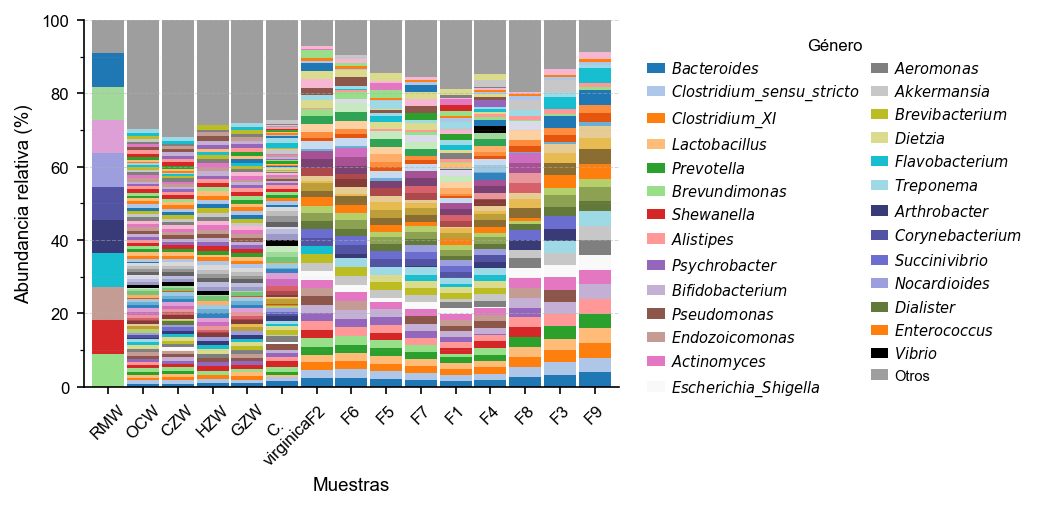

Cobertura mínima: 0.68
Cobertura mediana: 0.845
CZW             0.680486
OCW             0.702030
HZW             0.713080
GZW             0.720039
C. virginica    0.726447
F8              0.803718
F1              0.810574
F7              0.844624
F4              0.852996
F5              0.854905
F3              0.865312
F6              0.904326
RMW             0.909084
F9              0.911568
F2              0.928239
dtype: float64


In [540]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from textwrap import fill

# ===== opcional: ordenar muestras por similitud =====
try:
    from scipy.spatial.distance import pdist
    from scipy.cluster.hierarchy import linkage, leaves_list
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False

# =========================
# Parámetros ajustables
# =========================
COVERAGE_TARGET = 0.85   # Cobertura mínima por muestra (0.80–0.95 recomendado)
MAX_GENEROS     = 120    # Tope de seguridad (evita leyendas enormes)
GENERO_FORZADO  = "Vibrio"  # Se fuerza si aparece

# Filtros opcionales para depurar ruido (puedes desactivarlos poniendo 0)
MIN_GLOBAL_REL  = 0.002  # 0.2% del total global
MIN_PREVALENCIA = 0.15   # presente en ≥15% de muestras

# Leyenda: cuántos mostrar + patógenos clave
TOP_LEYENDA   = 25
PATOGENOS_SET = {
    "Escherichia/Shigella", "Vibrio", "Aeromonas",
    "Enterococcus", "Clostridium_sensu_stricto", "Clostridium_XI"
}

# =========================
# 1) Copia y limpieza básica
# =========================
df = df_all_16SG.copy()  # requiere: 'Género' y columnas de muestras

generos_a_eliminar = ['unknown_unclassified', 'TM7_genus_incertae_sedis']
df = df[~df['Género'].isin(generos_a_eliminar)]

df['Género'] = df['Género'].replace({
    'Escherichia-Shigella': 'Escherichia/Shigella',
})

cols_abund = [c for c in df.columns if c not in ['Género', 'p-values']]
if 'SumaTotal' in cols_abund:
    cols_abund.remove('SumaTotal')

df[cols_abund] = df[cols_abund].apply(pd.to_numeric, errors='coerce').fillna(0)

# =========================
# 2) Agregación por género
# =========================
abund_por_gen = df.groupby('Género')[cols_abund].sum()

# =========================
# 2.1) Filtros opcionales por relevancia global y prevalencia
#      (mantiene patógenos aunque sean raros)
# =========================
if MIN_GLOBAL_REL > 0 or MIN_PREVALENCIA > 0:
    total_global = abund_por_gen.sum().sum()
    global_rel = abund_por_gen.sum(axis=1) / max(total_global, 1.0)
    preval = (abund_por_gen > 0).sum(axis=1) / abund_por_gen.shape[1]
    mask_relev = (
        (global_rel >= MIN_GLOBAL_REL) |
        (preval >= MIN_PREVALENCIA) |
        (abund_por_gen.index.isin(PATOGENOS_SET))
    )
    abund_por_gen = abund_por_gen.loc[mask_relev].copy()

# =========================
# 3) Selección por COBERTURA mínima por muestra + forzar Vibrio
# =========================
# 3.1 Normaliza por muestra (proporciones, no %)
tot_por_muestra = abund_por_gen.sum(axis=0).replace(0, np.nan)
rel = abund_por_gen.div(tot_por_muestra, axis=1).fillna(0.0)

# 3.2 Lista global por abundancia total (desc)
orden_global = abund_por_gen.sum(axis=1).sort_values(ascending=False).index.tolist()

# 3.3 Arranque con géneros forzados si aparecen
seleccion = []
if (GENERO_FORZADO in rel.index) and (rel.loc[GENERO_FORZADO].sum() > 0):
    seleccion.append(GENERO_FORZADO)

def cobertura_actual(sel):
    """Cobertura por muestra con la selección vigente."""
    if not sel:
        return pd.Series(0.0, index=rel.columns)
    return rel.loc[sel].sum(axis=0).clip(upper=1.0)

# 3.4 Bucle codicioso hasta cubrir todas las muestras
cov = cobertura_actual(seleccion)
i = 0
while (cov.min() < COVERAGE_TARGET) and (len(seleccion) < MAX_GENEROS):
    while (i < len(orden_global)) and (orden_global[i] in seleccion):
        i += 1
    if i >= len(orden_global):
        break
    candidato = orden_global[i]
    seleccion.append(candidato)
    cov = cobertura_actual(seleccion)
    i += 1

# 3.5 Orden final por abundancia global descendente (para leyenda/colores)
seleccion_ordenada = abund_por_gen.loc[seleccion].sum(axis=1)\
                                  .sort_values(ascending=False).index.tolist()

# =========================
# 4) Normalización a % por muestra y "Otros"
# =========================
total_por_muestra = abund_por_gen.sum(axis=0).replace(0, np.nan)
full_norm = (abund_por_gen.T.div(total_por_muestra, axis=0).fillna(0) * 100)

top_norm = full_norm[seleccion_ordenada].copy()
mat_norm = top_norm.copy()
mat_norm['Otros'] = (100 - top_norm.sum(axis=1)).clip(lower=0)

# ===== (opcional) Ordenar muestras por similitud =====
if SCIPY_OK and mat_norm.shape[0] > 2:
    try:
        D = pdist(mat_norm.values, metric='braycurtis')
        Z = linkage(D, method='average')
        order_idx = leaves_list(Z)
        mat_norm = mat_norm.iloc[order_idx]
    except Exception:
        pass

# =========================
# 4.1) Reordenación manual del eje X: poner C. virginica (o O1..O10) antes de F3
# =========================
def move_group_before(seq, group_labels, before_label):
    """Mueve el conjunto 'group_labels' (en su orden original) justo antes de 'before_label'."""
    # preserva el orden interno del grupo según aparece en 'seq'
    group_in_order = [x for x in seq if x in group_labels]
    if not group_in_order or before_label not in seq:
        return seq
    seq_new = [x for x in seq if x not in group_in_order]
    idx = seq_new.index(before_label)
    # insertamos en orden (de atrás hacia adelante para mantener posiciones)
    for x in reversed(group_in_order):
        seq_new.insert(idx, x)
    return seq_new

orden_x = list(mat_norm.index)

# Aliases comunes
aliases_cvir = ["C. virginica", "Crassostrea virginica", "C. virginica (promedio)"]
before_aliases = ["F2", "HecesP8", "F-2"]  # posibles nombres para F3

# ¿Cuál 'F3' existe?
before = next((a for a in before_aliases if a in orden_x), None)

# ¿Existe una muestra única llamada "C. virginica"?
targets = [a for a in aliases_cvir if a in orden_x]

# Si no hay "C. virginica", intentamos mover el bloque de O1..O10
if not targets:
    # Detecta muestras tipo O1..O10 si están presentes en el eje
    oysters = [x for x in orden_x if re.fullmatch(r"O\d+", str(x))]
    if oysters:
        targets = oysters  # mover todo el bloque de ostiones

# Aplica el movimiento si hay referencia 'before' válida
if before and targets:
    orden_x = move_group_before(orden_x, targets, before)
    mat_norm = mat_norm.loc[orden_x]
# Si no encuentra etiquetas, no cambia nada y sigue el orden actual


# =========================
# 5) Plot “journal-ready”
# =========================
cols_plot = seleccion_ordenada + ['Otros']

mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.linewidth": 0.8,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 7,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica","Arial","DejaVu Sans"],
})

# --- Paleta lo-que-se-necesite ---
def make_palette(n_main):
    bancos = [plt.cm.tab20, plt.cm.tab20b, plt.cm.tab20c]  # 60 tonos antes de reciclar
    colores = []
    for banco in bancos:
        if len(colores) >= n_main:
            break
        m = min(n_main - len(colores), 20)
        colores += [banco(i) for i in range(m)]
    i = 0
    while len(colores) < n_main:
        colores.append(plt.cm.tab20(i % 20))
        i += 1
    return colores

n_main = max(0, len(cols_plot) - 1)  # todos menos "Otros"
palette_main = make_palette(n_main)
palette = palette_main + ["#9E9E9E"]  # gris para “Otros”
color_map = {g: c for g, c in zip(cols_plot, palette)}

# Colores fijos (si existen en la selección)
fixed_colors = {
    "Vibrio": "#000000",
    "Escherichia_Shigella": "#f9f9f9",
    "Enterococcus": "#ff7f0e"
}
for g, col in fixed_colors.items():
    if g in color_map:
        color_map[g] = col

# Respaldo por si faltara alguno (no debería)
default_color = "#808080"
for g in cols_plot:
    if g not in color_map:
        color_map[g] = default_color

def _sanitize(s): return s.replace('_', r'\_').replace('%', r'\%')
def italicize(lbl): return rf"$\it{{{_sanitize(lbl)}}}$" if lbl != "Otros" else lbl
def wrap_xticks(ax, width=10):
    ax.set_xticklabels([fill(t.get_text(), width) for t in ax.get_xticklabels()])

# --- Crear figura y graficar ---
fig, ax = plt.subplots(figsize=(7.09, 3.5))
mat_plot = mat_norm[cols_plot]
mat_plot.plot(
    kind='bar', stacked=True, ax=ax,
    color=[color_map[c] for c in cols_plot],
    width=0.92, edgecolor="none"
)

ax.set_ylabel("Abundancia relativa (%)")
ax.set_xlabel("Muestras")
ax.set_ylim(0, 100)
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(20))
ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(10))
ax.grid(axis="y", which="major", linestyle="--", linewidth=0.5, alpha=0.5)
ax.grid(axis="y", which="minor", linestyle=":",  linewidth=0.35, alpha=0.3)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", rotation=45)
wrap_xticks(ax, width=10)

# --- Leyenda reducida: Top global + patógenos + "Otros" ---
top_global = (abund_por_gen.loc[seleccion_ordenada]
              .sum(axis=1).sort_values(ascending=False)).index.tolist()
keep_legend = set(top_global[:TOP_LEYENDA]) | PATOGENOS_SET | {"Otros"}

handles_all, labels_all = ax.get_legend_handles_labels()
labels_all_sanit = [lbl for lbl in labels_all]  # sin itálicas para filtrar by name exacto

keep_idx = [i for i, lab in enumerate(labels_all_sanit) if lab in keep_legend]
handles_kept = [handles_all[i] for i in keep_idx]
labels_kept  = [italicize(labels_all_sanit[i]) for i in keep_idx]

n_items = len(labels_kept) - (1 if any(l.endswith("Otros") for l in labels_kept) else 0)
ncol = 1 if n_items <= 20 else (2 if n_items <= 40 else 3)

ax.legend(
    handles_kept, labels_kept,
    title="Género",
    bbox_to_anchor=(1.02, 1.0),
    loc="upper left",
    frameon=False,
    ncol=ncol,
    title_fontsize=8,
    columnspacing=0.8,
    handlelength=1.2,
    handletextpad=0.4,
    borderaxespad=0.8
)

fig.tight_layout()
fig.savefig("fig16S_generos_top_abundancia.tiff", dpi=600,
            pil_kwargs={'compression': 'tiff_lzw'})
fig.savefig("fig16S_generos_top_abundancia.pdf")
plt.show()

# =========================
# 6) Diagnóstico de cobertura
# =========================
sel_cov = abund_por_gen.loc[seleccion_ordenada].sum()
tot_cov = abund_por_gen.sum()
cobertura_por_muestra = (sel_cov / tot_cov).fillna(0)
print("Cobertura mínima:", cobertura_por_muestra.min().round(3))
print("Cobertura mediana:", cobertura_por_muestra.median().round(3))
print(cobertura_por_muestra.sort_values())
